# Семинар 4. Сегментация: U-Net, метрики IoU и Dice

Семинар идёт сразу после лекции 4 «Семантическая сегментация». На лекции была
постановка задачи и зоопарк архитектур; здесь мы всё это собираем руками
и проверяем измерением.

**Что сделаем:**

1. Сгенерируем датасет для сегментации — с **сильным дисбалансом классов**,
   объект занимает меньше процента кадра. На этом дисбалансе держится половина семинара.
2. Напишем метрики руками: pixel accuracy, IoU, Dice, mIoU — и увидим,
   как pixel accuracy врёт, а mIoU меняется от способа усреднения.
3. Разберём апсемплинг в PyTorch: `interpolate`, `MaxUnpool2d`, `ConvTranspose2d`;
   воспроизведём кодом тот самый пример 2×2 → 3×3 со слайда.
4. Посмотрим на шахматные артефакты и на то, когда они возникают.
5. Соберём **U-Net с нуля** — блоки, энкодер, декодер, skip-связи через `torch.cat`.
6. Сравним функции потерь: BCE, Dice loss и их комбинацию при дисбалансе.
7. Подберём порог бинаризации по валидации.
8. Отключим skip-связи и посмотрим, что именно они дают.
9. Разберём аугментации и главный подводный камень — синхронность маски и картинки.

**Как запускать.** Ноутбук работает и в Google Colab, и локально. Локально нужно:

```
pip install torch matplotlib numpy
```

Данные **генерируются кодом** — качать из интернета ничего не надо, и картинки
у всех получатся одинаковые. Полный прогон занимает около четырёх минут на обычном
процессоре, видеокарта не нужна.

⚠️ **Материала здесь больше, чем на 90 минут.** Ядро, без которого семинар теряет
смысл, — разделы **1, 2, 5, 6 и 7** (данные, метрики руками, U-Net, функции потерь,
порог). Разделы 3 и 4 (механика апсемплинга и шахматные артефакты) — подробный
разбор одного слайда лекции: если времени мало, из них хватит двух ячеек с готовым
примером 2×2 → 3×3 и карты вкладов. Разделы 8 и 9 (skip-связи, аугментации)
самостоятельны и переносятся на самостоятельное чтение без потерь; раздел 8 к тому же
самый долгий по счёту — в нём обучаются ещё две сети по 28 эпох.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(0)
np.random.seed(0)

# Считаем на CPU намеренно: картинки 64×64, сеть крошечная, на видеокарте выигрыш
# съест пересылка данных. Заодно у всех получатся одинаковые числа.
device = "cpu"
print("PyTorch:", torch.__version__)

PyTorch: 2.8.0


---

## 1. Данные: синтетические фигуры и их маски

Настоящие датасеты сегментации (Cityscapes, COCO) весят десятки гигабайт, и на семинаре
их не скачать. Поэтому **сгенерируем данные сами** — заодно получим ровно тот режим,
который нужен: разметка точная (маска считается аналитически, а не размечена руками),
а объект маленький.

Картинка 64×64: неоднородный фон (градиент плюс пара размытых пятен), на нём **одна
фигура** — круг, прямоугольник или треугольник — чуть светлее или темнее фона,
и сверху гауссов шум. Маска строится формулой, поэтому она идеальна.

Классов четыре: `0` — фон, `1` — круг, `2` — прямоугольник, `3` — треугольник.
Большую часть семинара мы решаем **бинарную** задачу «объект против фона»
(`mask > 0`), а многоклассовая разметка понадобится в разделе 2 для mIoU.

In [2]:
SIZE = 64
CLASSES = ["фон", "круг", "прямоугольник", "треугольник"]


def _disk(cy, cx, r, yy, xx):
    return (yy - cy) ** 2 + (xx - cx) ** 2 <= r * r


def _square(cy, cx, r, yy, xx):
    return (np.abs(yy - cy) <= 0.85 * r) & (np.abs(xx - cx) <= 0.85 * r)


def _triangle(cy, cx, r, yy, xx):
    # три полуплоскости: вершина сверху, основание снизу
    return ((yy - (cy - r)) >= 0) & ((yy - cy - 0.5 * r) <= 0) & \
           (np.abs(xx - cx) <= 0.9 * (yy - (cy - r)))


def make_sample(rng):
    """Одна картинка 64×64 и её маска с метками классов 0…3."""
    yy, xx = np.mgrid[0:SIZE, 0:SIZE].astype(np.float32)

    # неоднородный фон: линейный градиент + два широких пятна
    img = 0.35 + 0.15 * (xx / SIZE) - 0.10 * (yy / SIZE)
    for _ in range(2):
        by, bx = rng.uniform(0, SIZE, 2)
        img += rng.uniform(-0.12, 0.12) * np.exp(
            -((yy - by) ** 2 + (xx - bx) ** 2) / (2 * 22.0 ** 2))

    cls = int(rng.integers(1, 4))
    r = float(rng.uniform(2.5, 4.0))                 # фигура НАМЕРЕННО маленькая
    cy, cx = rng.uniform(r + 2, SIZE - r - 2, 2)
    shape_fn = (_disk, _square, _triangle)[cls - 1]
    m = shape_fn(cy, cx, r, yy, xx)

    # контраст фигуры небольшой и случайного знака: фигура бывает и светлее, и темнее
    delta = rng.choice([-1.0, 1.0]) * rng.uniform(0.10, 0.18)
    img = np.where(m, img + delta, img)
    img = img + rng.normal(0, 0.10, img.shape)       # шум

    mask = np.zeros((SIZE, SIZE), dtype=np.int64)
    mask[m] = cls
    return img.astype(np.float32), mask


def make_dataset(n, seed):
    rng = np.random.default_rng(seed)
    X = np.zeros((n, 1, SIZE, SIZE), dtype=np.float32)
    Y = np.zeros((n, SIZE, SIZE), dtype=np.int64)
    for i in range(n):
        X[i, 0], Y[i] = make_sample(rng)
    return torch.from_numpy(X), torch.from_numpy(Y)


t0 = time.time()
X_tr, Y_tr = make_dataset(400, seed=0)      # обучение
X_va, Y_va = make_dataset(120, seed=1)      # валидация: кривые и подбор порога
X_te, Y_te = make_dataset(120, seed=2)      # тест: только итоговые числа
print("сгенерировано за %.1f с" % (time.time() - t0))
print("обучение:", tuple(X_tr.shape), "| валидация:", tuple(X_va.shape),
      "| тест:", tuple(X_te.shape))

сгенерировано за 0.1 с
обучение: (400, 1, 64, 64) | валидация: (120, 1, 64, 64) | тест: (120, 1, 64, 64)


⚠️ Обратите внимание на **три** выборки, а не две. Валидация нужна не только для кривых:
в разделе 7 мы будем **подбирать по ней порог бинаризации**, а подобранный по выборке
гиперпараметр делает оценку на ней завышенной. Поэтому итоговые числа считаем на тесте,
которого не видел ни один наш выбор.

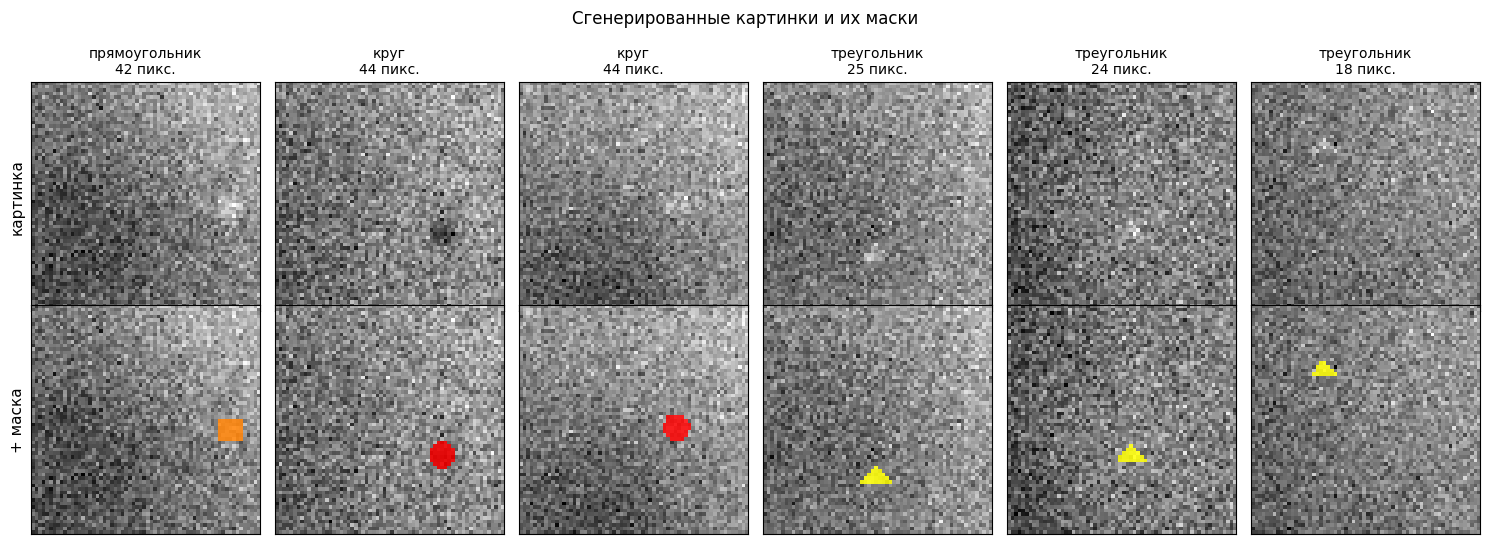

In [3]:
fig, axes = plt.subplots(2, 6, figsize=(15, 5.4))
for j in range(6):
    img, m = X_tr[j, 0].numpy(), Y_tr[j].numpy()
    cls = int(m.max())
    axes[0, j].imshow(img, cmap="gray")
    axes[0, j].set_title(f"{CLASSES[cls]}\n{(m > 0).sum()} пикс.", fontsize=10)
    axes[1, j].imshow(img, cmap="gray")
    axes[1, j].imshow(np.ma.masked_where(m == 0, m), cmap="autumn",
                      alpha=0.85, vmin=1, vmax=3, interpolation="nearest")
    for ax in (axes[0, j], axes[1, j]):
        ax.set_xticks([]); ax.set_yticks([])
axes[0, 0].set_ylabel("картинка", fontsize=11)
axes[1, 0].set_ylabel("+ маска", fontsize=11)
plt.suptitle("Сгенерированные картинки и их маски", y=1.0)
plt.tight_layout(); plt.show()

### Дисбаланс классов

Главное свойство этих данных — и главное свойство настоящих задач сегментации:
**объект занимает малую долю кадра.** Посчитаем.

доля пикселей объекта в обучающей выборке: 0.0070  (0.70%)
доля пикселей фона:                        0.9930  (99.30%)

  класс 0 (фон           )  0.9930  — картинок с этим классом: 400 из 400
  класс 1 (круг          )  0.0028  — картинок с этим классом: 137 из 400
  класс 2 (прямоугольник )  0.0024  — картинок с этим классом: 124 из 400
  класс 3 (треугольник   )  0.0018  — картинок с этим классом: 139 из 400


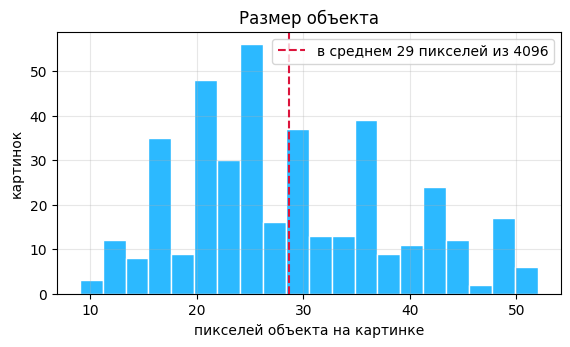

In [4]:
fg = (Y_tr > 0).float()
print("доля пикселей объекта в обучающей выборке: %.4f  (%.2f%%)"
      % (fg.mean(), 100 * fg.mean()))
print("доля пикселей фона:                        %.4f  (%.2f%%)"
      % (1 - fg.mean(), 100 * (1 - fg.mean())))
print()
for c in range(4):
    part = (Y_tr == c).float().mean().item()
    print("  класс %d (%-14s) %7.4f  — картинок с этим классом: %3d из %d"
          % (c, CLASSES[c], part, int(((Y_tr == c).any(dim=1).any(dim=1)).sum()), len(Y_tr)))

sizes = (Y_tr > 0).flatten(1).sum(1).numpy()
plt.figure(figsize=(6.5, 3.4))
plt.hist(sizes, bins=20, color="#2CB9FF", edgecolor="white")
plt.axvline(sizes.mean(), color="crimson", ls="--",
            label="в среднем %.0f пикселей из %d" % (sizes.mean(), SIZE * SIZE))
plt.xlabel("пикселей объекта на картинке"); plt.ylabel("картинок")
plt.title("Размер объекта"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

**0,70% кадра** — в среднем 29 пикселей объекта из 4096. Для сравнения: в Cityscapes класс
«дорога» занимает примерно треть изображения, а класс «светофор» — доли процента. Наша
задача ближе ко второму случаю, и это самый интересный режим: именно в нём разваливаются
наивные метрики и наивные функции потерь.

Заодно посмотрите на первую картинку: объект видно с трудом и глазами. Контраст фигуры
взят небольшим намеренно — иначе задача решается за две эпохи, и сравнивать функции
потерь становится не на чем.

---

## 2. Метрики руками

Разберёмся, что именно мы измеряем. Все три метрики считаются из одних и тех же
четырёх чисел: TP (правильно найденные пиксели объекта), FP (лишние), FN (пропущенные),
TN (правильно оставленный фон).

$$\text{pixel accuracy} = \frac{TP + TN}{TP + TN + FP + FN}$$

$$\text{IoU} = \frac{|A \cap B|}{|A \cup B|} = \frac{TP}{TP + FP + FN}
\qquad
\text{Dice} = \frac{2|A \cap B|}{|A| + |B|} = \frac{2\,TP}{2\,TP + FP + FN}$$

Разница между IoU и Dice ровно одна: Dice **считает пересечение дважды**, поэтому
он всегда мягче к ошибкам. Заметьте: **TN не входит ни в IoU, ни в Dice** — именно
поэтому они не ломаются от дисбаланса, а pixel accuracy ломается.

In [5]:
def confusion(pred, target):
    """TP, FP, FN, TN для бинарных масок (тензоры из 0 и 1, любой формы)."""
    pred = pred.bool(); target = target.bool()
    tp = (pred & target).sum().item()
    fp = (pred & ~target).sum().item()
    fn = (~pred & target).sum().item()
    tn = (~pred & ~target).sum().item()
    return tp, fp, fn, tn


def pixel_accuracy(pred, target):
    tp, fp, fn, tn = confusion(pred, target)
    return (tp + tn) / (tp + fp + fn + tn)


def iou_score(pred, target):
    tp, fp, fn, tn = confusion(pred, target)
    denom = tp + fp + fn
    return tp / denom if denom > 0 else float("nan")     # 0/0 — метрика не определена


def dice_score(pred, target):
    tp, fp, fn, tn = confusion(pred, target)
    denom = 2 * tp + fp + fn
    return 2 * tp / denom if denom > 0 else float("nan")


# Проверка на игрушечном примере, который можно пересчитать на бумаге
a = torch.zeros(4, 4); a[1:3, 1:3] = 1          # квадрат 2×2, 4 пикселя
b = torch.zeros(4, 4); b[2:4, 2:4] = 1          # такой же, сдвинут на (1, 1)
print("маска A:\n", a.int().numpy())
print("маска B:\n", b.int().numpy())
print("TP, FP, FN, TN =", confusion(a, b))
print("пересечение 1, объединение 7  →  IoU = 1/7 = %.4f, посчитано %.4f"
      % (1 / 7, iou_score(a, b)))
print("Dice = 2·1/(4+4) = %.4f, посчитано %.4f" % (2 / 8, dice_score(a, b)))

маска A:
 [[0 0 0 0]
 [0 1 1 0]
 [0 1 1 0]
 [0 0 0 0]]
маска B:
 [[0 0 0 0]
 [0 0 0 0]
 [0 0 1 1]
 [0 0 1 1]]
TP, FP, FN, TN = (1, 3, 3, 9)
пересечение 1, объединение 7  →  IoU = 1/7 = 0.1429, посчитано 0.1429
Dice = 2·1/(4+4) = 0.2500, посчитано 0.2500


### 2.1. Почему pixel accuracy врёт

Самый дешёвый в мире сегментатор: **предсказываем, что всё — фон.** Никакой модели,
ни одного параметра. Посмотрим, что скажут метрики.

In [6]:
gt = (Y_va > 0).float()

predictors = {
    "«всё фон»":        torch.zeros_like(gt),
    "«всё объект»":     torch.ones_like(gt),
    "случайные 1%":     (torch.rand(gt.shape, generator=torch.Generator().manual_seed(0)) < 0.01).float(),
    "правда, сдвинутая на 2 пикселя": torch.roll(gt, shifts=(2, 2), dims=(1, 2)),
    "идеальное предсказание": gt.clone(),
}

print("%-34s %10s %8s %8s" % ("предсказание", "accuracy", "IoU", "Dice"))
print("-" * 64)
for name, p in predictors.items():
    print("%-34s %10.4f %8.4f %8.4f"
          % (name, pixel_accuracy(p, gt), iou_score(p, gt), dice_score(p, gt)))

предсказание                         accuracy      IoU     Dice
----------------------------------------------------------------
«всё фон»                              0.9933   0.0000   0.0000
«всё объект»                           0.0067   0.0067   0.0134
случайные 1%                           0.9832   0.0036   0.0072
правда, сдвинутая на 2 пикселя         0.9920   0.2545   0.4057
идеальное предсказание                 1.0000   1.0000   1.0000


Вот он, главный подвох сегментации при дисбалансе.

**Предсказание «всё фон» даёт pixel accuracy около 0.99** — почти отличницу по обычной
классификации, — и при этом **IoU и Dice равны нулю**: объект не найден ни разу.
Отчёт «наша модель размечает 99% пикселей правильно» технически верен и абсолютно
бессодержателен.

Причина видна прямо в формулах: в pixel accuracy числитель содержит TN, а фона
у нас 99% кадра, и он весь угадывается даром. В IoU и Dice слагаемого TN нет вовсе —
они считают только по объекту.

⚠️ Отсюда практическое правило: **в задачах сегментации pixel accuracy не докладывают
как основную метрику.** Её ещё можно смотреть как вспомогательную, но решения по ней
принимать нельзя.

### 2.2. Связь IoU и Dice

Эти две метрики монотонно связаны:

$$\text{Dice} = \frac{2\,\text{IoU}}{1 + \text{IoU}}
\qquad\Longleftrightarrow\qquad
\text{IoU} = \frac{\text{Dice}}{2 - \text{Dice}}$$

Проверим численно на произвольных предсказаниях: формула должна выполняться точно,
а не приближённо.

предсказание                IoU     Dice   2I/(1+I)    разница
--------------------------------------------------------------
точное совпадение        1.0000   1.0000     1.0000   0.00e+00
сжатая на 1 пиксель      0.3156   0.4798     0.4798   5.55e-17
сдвиг на 1 пиксель       0.5115   0.6769     0.6769   0.00e+00
расширенная на 1         0.4989   0.6657     0.6657   1.11e-16
сдвиг на 2 пикселя       0.2545   0.4057     0.4057   0.00e+00
расширенная на 2         0.3032   0.4653     0.4653   5.55e-17


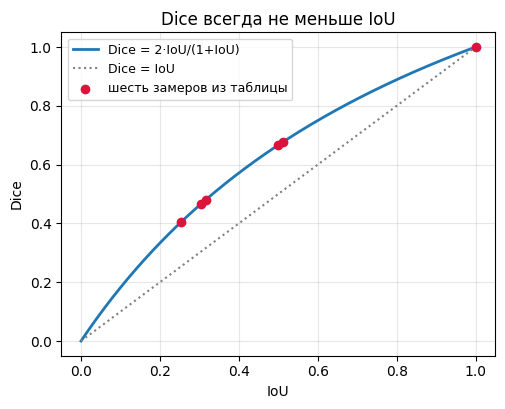

In [7]:
def dilate(m, w):
    return F.max_pool2d(m, 2 * w + 1, stride=1, padding=w)


def erode(m, w):
    return -F.max_pool2d(-m, 2 * w + 1, stride=1, padding=w)


g4 = gt.unsqueeze(1)
variants = {
    "точное совпадение":   g4,
    "сжатая на 1 пиксель": erode(g4, 1),
    "сдвиг на 1 пиксель":  torch.roll(g4, shifts=(1, 1), dims=(2, 3)),
    "расширенная на 1":    dilate(g4, 1),
    "сдвиг на 2 пикселя":  torch.roll(g4, shifts=(2, 2), dims=(2, 3)),
    "расширенная на 2":    dilate(g4, 2),
}

print("%-22s %8s %8s %10s %10s" % ("предсказание", "IoU", "Dice", "2I/(1+I)", "разница"))
print("-" * 62)
rows = []
for name, p in variants.items():
    i, d = iou_score(p, g4), dice_score(p, g4)
    rows.append((i, d))
    print("%-22s %8.4f %8.4f %10.4f %10.2e"
          % (name, i, d, 2 * i / (1 + i), abs(d - 2 * i / (1 + i))))

xs = np.linspace(0, 1, 200)
plt.figure(figsize=(5.6, 4.2))
plt.plot(xs, 2 * xs / (1 + xs), lw=2, label="Dice = 2·IoU/(1+IoU)")
plt.plot(xs, xs, ls=":", color="gray", label="Dice = IoU")
plt.scatter([r[0] for r in rows], [r[1] for r in rows], color="crimson", zorder=3,
            label="шесть замеров из таблицы")
plt.xlabel("IoU"); plt.ylabel("Dice"); plt.legend(fontsize=9); plt.grid(alpha=0.3)
plt.title("Dice всегда не меньше IoU"); plt.show()

Разница — на уровне машинной точности, связь точная.

Практический вывод: **ранжировать модели можно любой из двух метрик — порядок будет
один и тот же** (функция `2x/(1+x)` монотонна). Но абсолютные числа не сравнивайте между
собой: Dice систематически выше. IoU 0.5 — это Dice 0.667, и статья, отчитавшаяся
«Dice 0.85», в терминах IoU показала 0.74.

### 2.3. mIoU: усреднение по классам

Когда классов больше двух, считают IoU для каждого класса отдельно и усредняют —
это **mIoU** (mean IoU), стандартная метрика Cityscapes и PASCAL VOC. Для класса $c$:

$$\text{IoU}_c = \frac{|\{ \hat y = c\} \cap \{y = c\}|}{|\{\hat y = c\} \cup \{y = c\}|}$$

Возьмём многоклассовую разметку и сымитируем предсказание — сдвинем правду на пару
пикселей и перепутаем класс у каждой десятой картинки. Так мы точно знаем, где модель
ошиблась, и можем проверять метрику, а не модель.

In [8]:
def fake_prediction(mask, shift=(2, 1), confuse_every=10, seed=0):
    """Правдоподобное «предсказание»: сдвиг маски + путаница классов."""
    rng = np.random.default_rng(seed)
    pred = torch.roll(mask, shifts=shift, dims=(1, 2)).clone()
    for i in range(len(pred)):
        if i % confuse_every == 0:                       # подменяем класс фигуры
            present = int(pred[i].max())
            if present > 0:
                wrong = 1 + (present % 3)
                pred[i][pred[i] == present] = wrong
    return pred


P_va = fake_prediction(Y_va)
print("совпадает с правдой по классу у %.1f%% пикселей"
      % (100 * (P_va == Y_va).float().mean()))


def class_parts(pred, target, n_classes=4):
    """Пересечения и объединения по каждому классу (в пикселях)."""
    inter = np.zeros(n_classes); union = np.zeros(n_classes)
    for c in range(n_classes):
        pc, tc = (pred == c), (target == c)
        inter[c] = (pc & tc).sum().item()
        union[c] = (pc | tc).sum().item()
    return inter, union


inter, union = class_parts(P_va, Y_va)
print("\nIoU по классам, накопленный по всему датасету:")
for c in range(4):
    print("  %-14s пересечение %7d, объединение %7d → IoU %.4f"
          % (CLASSES[c], inter[c], union[c], inter[c] / union[c]))
print("mIoU = %.4f" % (inter / union).mean())

совпадает с правдой по классу у 99.3% пикселей

IoU по классам, накопленный по всему датасету:
  фон            пересечение  486555, объединение  489875 → IoU 0.9932
  круг           пересечение     687, объединение    1967 → IoU 0.3493
  прямоугольник  пересечение     528, объединение    1794 → IoU 0.2943
  треугольник    пересечение     272, объединение    1362 → IoU 0.1997
mIoU = 0.4591


### 2.4. ⚠️ Подводный камень: усреднение по батчу против накопления по датасету

А теперь — место, где ошибаются чаще всего. Есть два способа посчитать mIoU:

- **(A) по картинкам:** для каждой картинки посчитать mIoU и усреднить по датасету;
- **(B) по датасету:** накопить пересечения и объединения по всем картинкам,
  и только в самом конце поделить.

Это **разные числа**, и разница не маленькая. Причина — в картинках, где класса нет
вовсе: у нас на каждой картинке ровно одна фигура, значит как минимум два класса
из четырёх отсутствуют и в правде, и в предсказании. Для них $0/0$ — IoU не определён,
и что с ним делать, приходится решать руками.

In [9]:
per_image_one, per_image_skip, per_image_zero = [], [], []
for i in range(len(Y_va)):
    it, un = class_parts(P_va[i], Y_va[i])
    present = un > 0
    per_image_one.append(np.where(present, it / np.maximum(un, 1), 1.0).mean())   # 0/0 → 1
    per_image_zero.append(np.where(present, it / np.maximum(un, 1), 0.0).mean())  # 0/0 → 0
    per_image_skip.append((it[present] / un[present]).mean())                     # пропустить

inter, union = class_parts(P_va, Y_va)

print("(A) среднее по картинкам, отсутствующий класс считаем идеальным (0/0 → 1): %.4f"
      % np.mean(per_image_one))
print("(A) среднее по картинкам, отсутствующие классы пропускаем:                 %.4f"
      % np.mean(per_image_skip))
print("(A) среднее по картинкам, отсутствующий класс считаем нулевым (0/0 → 0):  %.4f"
      % np.mean(per_image_zero))
print("(B) накопление по всему датасету (так считают Cityscapes и PASCAL VOC):   %.4f"
      % (inter / union).mean())

(A) среднее по картинкам, отсутствующий класс считаем идеальным (0/0 → 1): 0.7931
(A) среднее по картинкам, отсутствующие классы пропускаем:                 0.6197
(A) среднее по картинкам, отсутствующий класс считаем нулевым (0/0 → 0):  0.3181
(B) накопление по всему датасету (так считают Cityscapes и PASCAL VOC):   0.4591


Четыре способа посчитать «одну и ту же» метрику для **одного и того же предсказания** —
и четыре разных числа. Разброс больше, чем выигрыш от большинства архитектурных улучшений,
за которые борются в статьях.

Почему так:

- **0/0 → 1** завышает сильнее всех: на каждой картинке два класса отсутствуют,
  и они даром приносят по единице в среднее. Половина метрики оказывается ни о чём;
- **0/0 → 0**, наоборот, занижает: за отсутствие класса модель штрафуется, хотя
  она ничего не сделала не так;
- **пропускать отсутствующие** — честнее, но у каждой картинки тогда усредняется
  по своему числу классов, и мелкие объекты весят столько же, сколько крупные;
- **накопление по датасету** — стандарт. Каждый пиксель входит в метрику ровно один раз,
  независимо от того, на какой он картинке.

⚠️ Практическое правило: **метрику по датасету накапливают, а не усредняют по батчам.**
Накопите `intersection` и `union` в буферы, а поделите один раз в конце эпохи. Если
в вашем коде есть строка вида `iou = np.mean(batch_ious)` — вы считаете не то, что
считают в статьях, с которыми сравниваетесь.

---

## 3. Апсемплинг в PyTorch

Энкодер уменьшил картинку в 8 раз, а на выходе нужна маска исходного размера. Значит,
разрешение надо вернуть. Способов несколько, и на лекции они были на одном слайде —
здесь потрогаем каждый.

### 3.1. Интерполяция: `F.interpolate` и `nn.Upsample`

Самый простой вариант: без обучаемых параметров вообще.

In [10]:
small = torch.tensor([[[[1., 2.], [3., 4.]]]])
print("вход 2×2:\n", small[0, 0].numpy())

near = F.interpolate(small, scale_factor=2, mode="nearest")
bil = F.interpolate(small, scale_factor=2, mode="bilinear", align_corners=False)
print("\nnearest 4×4 (каждое значение скопировано в квадрат 2×2):\n", near[0, 0].numpy())
print("\nbilinear 4×4 (значения усреднены по соседям):\n", bil[0, 0].numpy().round(3))

print("\nобучаемых параметров у nn.Upsample:",
      sum(p.numel() for p in nn.Upsample(scale_factor=2).parameters()))

вход 2×2:
 [[1. 2.]
 [3. 4.]]

nearest 4×4 (каждое значение скопировано в квадрат 2×2):
 [[1. 1. 2. 2.]
 [1. 1. 2. 2.]
 [3. 3. 4. 4.]
 [3. 3. 4. 4.]]

bilinear 4×4 (значения усреднены по соседям):
 [[1.   1.25 1.75 2.  ]
 [1.5  1.75 2.25 2.5 ]
 [2.5  2.75 3.25 3.5 ]
 [3.   3.25 3.75 4.  ]]

обучаемых параметров у nn.Upsample: 0


`nn.Upsample` — это тот же `F.interpolate`, завёрнутый в модуль, чтобы его можно было
положить в `nn.Sequential`. Параметров у него ноль: **интерполяция ничему не учится.**

⚠️ Про `align_corners`. У `bilinear` есть этот флаг, и он меняет результат.
При `align_corners=False` (по умолчанию с версии 0.4) пиксель считается квадратиком,
и координаты центров пересчитываются честно; при `True` — точкой, и крайние точки
входа и выхода приколачиваются друг к другу. Значение по умолчанию менялось в истории
PyTorch, поэтому в чужом коде его стоит проверять глазами.

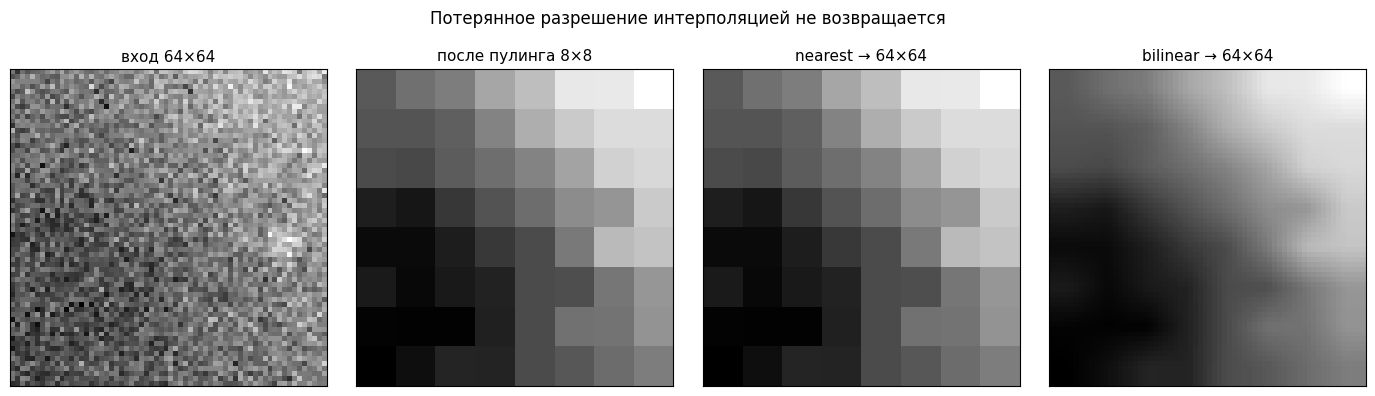

In [11]:
img = X_tr[0, 0]
lowres = F.avg_pool2d(img[None, None], 8)          # 64×64 → 8×8, как после энкодера
ups = {
    "вход 64×64": img,
    "после пулинга 8×8": lowres[0, 0],
    "nearest → 64×64": F.interpolate(lowres, size=(64, 64), mode="nearest")[0, 0],
    "bilinear → 64×64": F.interpolate(lowres, size=(64, 64), mode="bilinear",
                                      align_corners=False)[0, 0],
}
fig, axes = plt.subplots(1, 4, figsize=(14, 3.8))
for ax, (name, a) in zip(axes, ups.items()):
    ax.imshow(a.numpy(), cmap="gray", interpolation="nearest")
    ax.set_title(name, fontsize=11); ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Потерянное разрешение интерполяцией не возвращается", y=1.03)
plt.tight_layout(); plt.show()

Картинка объясняет, зачем вообще нужны skip-связи: после восьмикратного сжатия
информации о точном положении границы в тензоре **уже нет**, и никакая интерполяция
её не восстановит. `nearest` даёт кубики, `bilinear` — размытое пятно; фигуры не видно
ни там, ни там.

### 3.2. `MaxUnpool2d`: возвращаем значения туда, откуда брали

Идея SegNet: при `MaxPool2d` запомнить **индексы** максимумов и при апсемплинге положить
значения ровно на эти места, а остальное занулить.

In [12]:
z = torch.arange(16.).reshape(1, 1, 4, 4)
pool = nn.MaxPool2d(2, return_indices=True)      # !!! return_indices=True
pooled, indices = pool(z)
unpooled = nn.MaxUnpool2d(2)(pooled, indices)

print("вход 4×4:\n", z[0, 0].int().numpy())
print("\nпосле MaxPool2d(2):\n", pooled[0, 0].int().numpy())
print("индексы максимумов (в развёрнутом виде, 0…15):\n", indices[0, 0].numpy())
print("\nпосле MaxUnpool2d(2):\n", unpooled[0, 0].int().numpy())
print("\nненулевых значений на выходе:", int((unpooled != 0).sum()), "из", unpooled.numel())

вход 4×4:
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]
 [12 13 14 15]]

после MaxPool2d(2):
 [[ 5  7]
 [13 15]]
индексы максимумов (в развёрнутом виде, 0…15):
 [[ 5  7]
 [13 15]]

после MaxUnpool2d(2):
 [[ 0  0  0  0]
 [ 0  5  0  7]
 [ 0  0  0  0]
 [ 0 13  0 15]]

ненулевых значений на выходе: 4 из 16


Выход разреженный: три четверти позиций — нули, их потом «залечивают» обычными свёртками.

⚠️ Главная практическая деталь: `MaxUnpool2d` **нельзя вызвать без индексов**, а индексы
берутся от конкретного `MaxPool2d`. Значит, архитектура обязана быть симметричной
и хранить индексы всех пулингов до конца прямого прохода. Это ровно то, за что SegNet
хвалили (памяти меньше, чем на skip-связи с полными картами признаков) и ровно то,
почему победил U-Net: `torch.cat` проще и работает лучше.

### 3.3. `ConvTranspose2d`: апсемплинг, который учится

Транспонированная свёртка (она же deconvolution, хотя это название неверное —
математической деконволюцией она не является). Механика: **каждый входной пиксель
кладёт на выход всё ядро, умноженное на своё значение**, вклады складываются.

Воспроизведём пример со слайда лекции: вход 2×2 `[[0,1],[2,3]]`, ядро 2×2 `[[0,1],[2,3]]`,
stride 1. Сначала посчитаем руками, потом сверим с PyTorch.

In [13]:
x = np.array([[0, 1], [2, 3]])
k = np.array([[0, 1], [2, 3]])

manual = np.zeros((3, 3), dtype=int)
print("вход:\n", x, "\nядро:\n", k, "\n")
for i in range(2):
    for j in range(2):
        term = np.zeros((3, 3), dtype=int)
        term[i:i + 2, j:j + 2] = x[i, j] * k         # ядро, сдвинутое в позицию (i, j)
        manual += term
        print("вклад входа x[%d,%d] = %d (ядро, умноженное на %d, сдвиг (%d,%d)):"
              % (i, j, x[i, j], x[i, j], i, j))
        print(term, "\n")
print("сумма вкладов — выход 3×3:\n", manual)

вход:
 [[0 1]
 [2 3]] 
ядро:
 [[0 1]
 [2 3]] 

вклад входа x[0,0] = 0 (ядро, умноженное на 0, сдвиг (0,0)):
[[0 0 0]
 [0 0 0]
 [0 0 0]] 

вклад входа x[0,1] = 1 (ядро, умноженное на 1, сдвиг (0,1)):
[[0 0 1]
 [0 2 3]
 [0 0 0]] 

вклад входа x[1,0] = 2 (ядро, умноженное на 2, сдвиг (1,0)):
[[0 0 0]
 [0 2 0]
 [4 6 0]] 

вклад входа x[1,1] = 3 (ядро, умноженное на 3, сдвиг (1,1)):
[[0 0 0]
 [0 0 3]
 [0 6 9]] 

сумма вкладов — выход 3×3:
 [[ 0  0  1]
 [ 0  4  6]
 [ 4 12  9]]


In [14]:
xt = torch.tensor(x, dtype=torch.float32).reshape(1, 1, 2, 2)
kt = torch.tensor(k, dtype=torch.float32).reshape(1, 1, 2, 2)
torch_out = F.conv_transpose2d(xt, kt, stride=1)[0, 0].int().numpy()

print("PyTorch (F.conv_transpose2d):\n", torch_out)
print("\nсовпало с ручным расчётом:", bool((torch_out == manual).all()))
print("ожидалось со слайда [[0,0,1],[0,4,6],[4,12,9]]:",
      bool((torch_out == np.array([[0, 0, 1], [0, 4, 6], [4, 12, 9]])).all()))

PyTorch (F.conv_transpose2d):
 [[ 0  0  1]
 [ 0  4  6]
 [ 4 12  9]]

совпало с ручным расчётом: True
ожидалось со слайда [[0,0,1],[0,4,6],[4,12,9]]: True


⚠️ Тонкость, из-за которой ручной расчёт может не сойтись с библиотечным: обычная свёртка
в PyTorch (`conv2d`) — это на самом деле **корреляция**, ядро не переворачивается.
Транспонированная свёртка симметрично устроена так же: `conv_transpose2d` раскладывает
ядро **как есть**. Если бы кто-то из двух переворачивал ядро, числа бы разошлись —
мы это только что проверили прямой суммой вкладов.

И ещё: веса `ConvTranspose2d` имеют форму `(in_channels, out_channels, kH, kW)` —
первые две размерности **переставлены** по сравнению с `Conv2d`. Забыть об этом
и не понять, почему не сходятся формы, — классическая ошибка.

### 3.4. Арифметика размеров

Размер выхода транспонированной свёртки:

$$H_{out} = (H_{in} - 1)\cdot\text{stride} - 2\cdot\text{padding}
+ \text{dilation}\cdot(\text{kernel} - 1) + \text{output\_padding} + 1$$

Для `dilation = 1` это просто $(H_{in}-1)\cdot s - 2p + k + op$. Проверим формулу
перебором и заодно найдём наборы, которые дают ровно удвоение.

In [15]:
def out_size(h, k, s, p=0, op=0, d=1):
    return (h - 1) * s - 2 * p + d * (k - 1) + op + 1


print("%-28s %10s %10s %8s" % ("конфигурация", "формула", "PyTorch", "сошлось"))
print("-" * 60)
cases = [(8, 2, 2, 0, 0), (8, 3, 2, 1, 1), (8, 4, 2, 1, 0),
         (8, 3, 2, 0, 0), (8, 3, 1, 1, 0), (2, 2, 1, 0, 0)]
for h, k, s, p, op in cases:
    formula = out_size(h, k, s, p, op)
    real = F.conv_transpose2d(torch.zeros(1, 1, h, h), torch.zeros(1, 1, k, k),
                              stride=s, padding=p, output_padding=op).shape[-1]
    tag = "k=%d s=%d p=%d op=%d" % (k, s, p, op)
    print("%-28s %10d %10d %8s" % ("вход %d, %s" % (h, tag), formula, real,
                                   "да" if formula == real else "НЕТ"))

print("\nнаборы, которые дают ровно ×2 из 8 в 16:")
for k in range(2, 7):
    for p in range(0, 4):
        for op in range(0, 2):
            if out_size(8, k, 2, p, op) == 16:
                print("  kernel=%d, stride=2, padding=%d, output_padding=%d" % (k, p, op))

конфигурация                    формула    PyTorch  сошлось
------------------------------------------------------------
вход 8, k=2 s=2 p=0 op=0             16         16       да
вход 8, k=3 s=2 p=1 op=1             16         16       да
вход 8, k=4 s=2 p=1 op=0             16         16       да
вход 8, k=3 s=2 p=0 op=0             17         17       да
вход 8, k=3 s=1 p=1 op=0              8          8       да
вход 2, k=2 s=1 p=0 op=0              3          3       да

наборы, которые дают ровно ×2 из 8 в 16:
  kernel=2, stride=2, padding=0, output_padding=0
  kernel=3, stride=2, padding=1, output_padding=1
  kernel=4, stride=2, padding=1, output_padding=0
  kernel=5, stride=2, padding=2, output_padding=1
  kernel=6, stride=2, padding=2, output_padding=0


Отсюда три рецепта удвоения, которые вы увидите в чужом коде:

- `ConvTranspose2d(c_in, c_out, kernel_size=2, stride=2)` — ровно удвоение, без padding.
  Так сделано в оригинальном U-Net и так сделаем мы;
- `ConvTranspose2d(c_in, c_out, kernel_size=4, stride=2, padding=1)` — тоже удвоение,
  и, как увидим в разделе 4, **без шахматных артефактов**;
- `kernel_size=3, stride=2, padding=1, output_padding=1` — тоже даёт ×2, и именно
  этот вариант артефакты и производит.

---

## 4. Шахматные артефакты

Откуда берётся «шахматная доска» на выходе транспонированной свёртки. Каждый вход
кладёт на выход квадрат `kernel × kernel`, а соседние входы отстоят на `stride`.
Если `kernel` не делится на `stride`, то **разные выходные пиксели получают разное число
вкладов**, и по выходу идёт регулярная рябь.

Посчитаем карту числа вкладов честно: подадим на вход единицы, поставим ядро из единиц —
тогда значение выходного пикселя и есть число вкладов, которое он получил.

In [16]:
def contribution_map(n, kernel, stride, trim=True):
    """Сколько вкладов получает каждый выходной пиксель.

    trim=True обрезает поля шириной kernel − stride. Это ОБЯЗАТЕЛЬНО: на краях
    вкладов меньше у любого ядра просто потому, что за границей входа ничего нет.
    Без обрезки оба варианта дают одинаковый разброс 1…4, и весь тезис рассыпается.
    """
    x = torch.ones(1, 1, n, n)
    w = torch.ones(1, 1, kernel, kernel)
    out = F.conv_transpose2d(x, w, stride=stride)[0, 0].numpy()
    m = kernel - stride
    if trim and m > 0:
        out = out[m:out.shape[0] - m, m:out.shape[1] - m]
    return out


print("%-22s %7s %7s %7s %10s" % ("конфигурация", "min", "max", "std", "размер"))
print("-" * 58)
for trim in (False, True):
    print("-- поля %s" % ("НЕ обрезаны (так делать нельзя)" if not trim else "обрезаны"))
    for kernel in (3, 4):
        c = contribution_map(12, kernel, 2, trim=trim)
        print("   k=%d, stride=2        %7.0f %7.0f %7.3f %10s"
              % (kernel, c.min(), c.max(), c.std(), "%d×%d" % c.shape))

конфигурация               min     max     std     размер
----------------------------------------------------------
-- поля НЕ обрезаны (так делать нельзя)
   k=3, stride=2              1       4   1.040      25×25
   k=4, stride=2              1       4   0.951      26×26
-- поля обрезаны
   k=3, stride=2              1       4   1.074      23×23
   k=4, stride=2              4       4   0.000      22×22


⚠️ Верхняя половина таблицы — ловушка, в которую легко попасть: **без обрезки полей
`k=3` и `k=4` выглядят одинаково**, оба дают разброс 1…4, и никакой разницы между ними
не видно. На краях вкладов мало у любого ядра — это краевой эффект, к шахматной доске
отношения не имеющий. Смотреть надо на **внутреннюю часть** карты, отступив
`kernel − stride` пикселей от каждого края.

После обрезки картина однозначная: при `k=4, stride=2` все внутренние пиксели получают
поровну вкладов (`std = 0`), при `k=3, stride=2` — от 1 до 4.

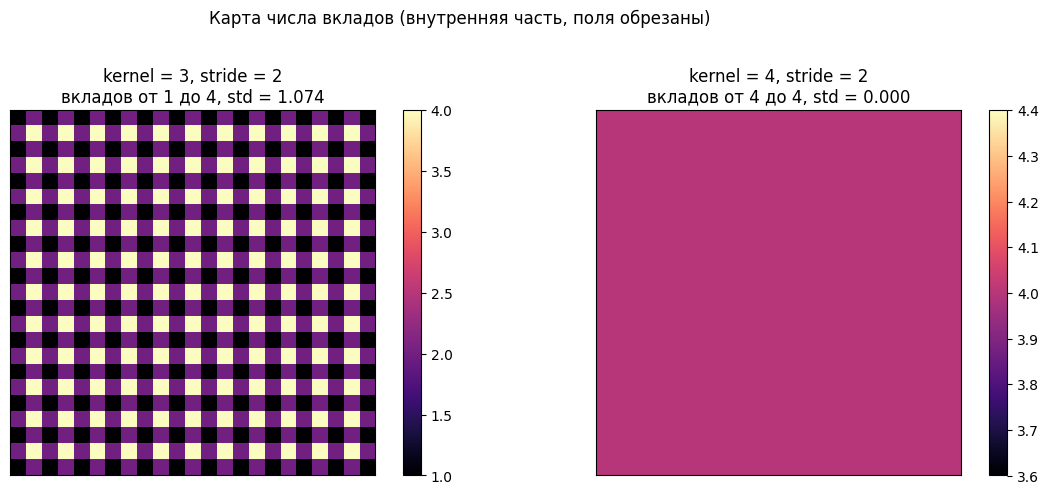

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, kernel in zip(axes, (3, 4)):
    c = contribution_map(12, kernel, 2)
    im = ax.imshow(c, cmap="magma", interpolation="nearest")
    ax.set_title("kernel = %d, stride = %d\nвкладов от %.0f до %.0f, std = %.3f"
                 % (kernel, 2, c.min(), c.max(), c.std()), fontsize=12)
    ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(im, ax=ax, fraction=0.046)
plt.suptitle("Карта числа вкладов (внутренняя часть, поля обрезаны)", y=1.02)
plt.tight_layout(); plt.show()

Слева — та самая шахматная доска. Справа — ровное поле.

Правило простое: **`kernel_size` должен делиться на `stride`.** Для удвоения это
`kernel_size=2, stride=2` или `kernel_size=4, stride=2, padding=1`. Популярный
`kernel_size=3, stride=2` артефакты производит.

### 4.1. Артефакты на настоящем сигнале

Карта вкладов — это про геометрию. Посмотрим, как та же геометрия выглядит на выходе
настоящего слоя: подадим ровный вход (все единицы) и поставим **одинаковые** веса —
тогда всё, что появится на выходе, создано исключительно устройством слоя. Заодно
сравним с альтернативой из лекции: **`Upsample(bilinear) + Conv2d`**.

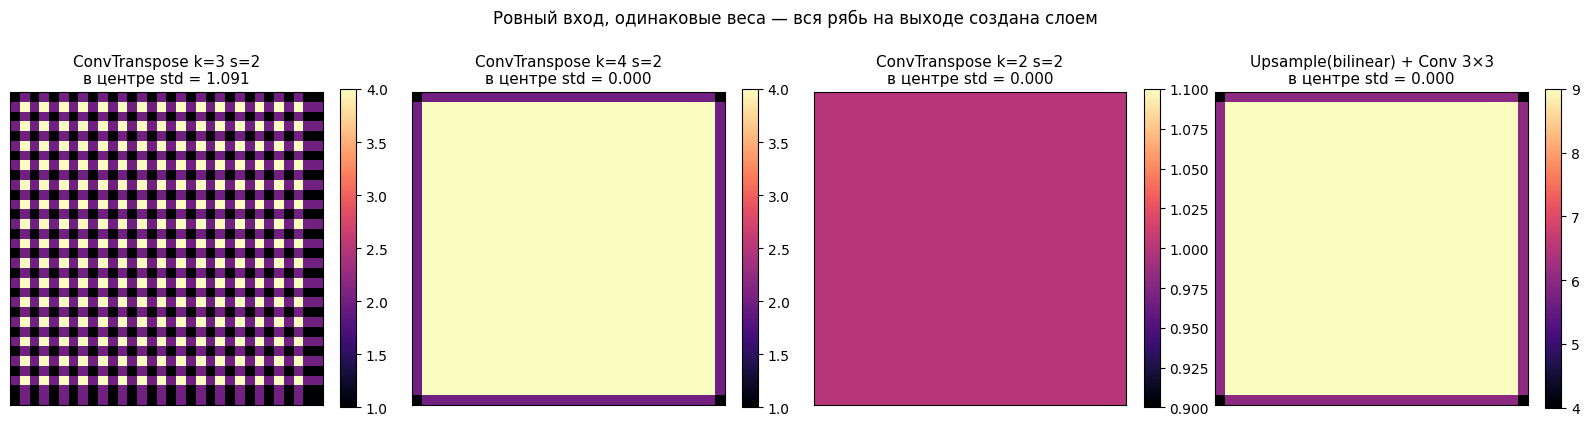

ConvTranspose k=3 s=2            центр: min 1.00, max 4.00, std 1.0907
ConvTranspose k=4 s=2            центр: min 4.00, max 4.00, std 0.0000
ConvTranspose k=2 s=2            центр: min 1.00, max 1.00, std 0.0000
Upsample(bilinear) + Conv 3×3    центр: min 9.00, max 9.00, std 0.0000


In [18]:
feat = torch.ones(1, 1, 16, 16)          # ровный вход: любая рябь на выходе — от слоя

variants = {}
for kernel, pad, opad in ((3, 1, 1), (4, 1, 0), (2, 0, 0)):
    layer = nn.ConvTranspose2d(1, 1, kernel, stride=2, padding=pad,
                               output_padding=opad, bias=False)
    nn.init.constant_(layer.weight, 1.0)       # веса одинаковые — остаётся чистая геометрия
    with torch.no_grad():
        variants["ConvTranspose k=%d s=2" % kernel] = layer(feat)[0, 0]

smooth = nn.Sequential(nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),
                       nn.Conv2d(1, 1, 3, padding=1, bias=False))
nn.init.constant_(smooth[1].weight, 1.0)
with torch.no_grad():
    variants["Upsample(bilinear) + Conv 3×3"] = smooth(feat)[0, 0]

fig, axes = plt.subplots(1, 4, figsize=(16, 4.2))
for ax, (name, out) in zip(axes, variants.items()):
    core = out[4:-4, 4:-4]                    # смотрим внутреннюю часть, без краёв
    im = ax.imshow(out.numpy(), cmap="magma", interpolation="nearest")
    ax.set_title("%s\nв центре std = %.3f" % (name, core.std()), fontsize=11)
    ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(im, ax=ax, fraction=0.046)
plt.suptitle("Ровный вход, одинаковые веса — вся рябь на выходе создана слоем", y=1.03)
plt.tight_layout(); plt.show()

for name, out in variants.items():
    core = out[4:-4, 4:-4]
    print("%-32s центр: min %.2f, max %.2f, std %.4f"
          % (name, core.min(), core.max(), core.std()))

Вот и весь эффект. `k=3, stride=2` при абсолютно ровном входе и одинаковых весах
выдаёт регулярную решётку — сеть потом вынуждена компенсировать её обучением,
и на реальных картинках это видно как характерная сетка на масках и на генерациях GAN.
`k=4` и `k=2` при тех же условиях дают ровный выход.

`Upsample(bilinear) + Conv2d` — распространённая замена: артефактов нет по построению.
Обучаемые параметры здесь только у свёртки (для 3×3 их девять на пару каналов против
шестнадцати у `ConvTranspose2d` с `kernel=4`), сам апсемплинг ничему не учится.
В современном коде чаще берут именно этот вариант.

⚠️ Оговорка, чтобы не переносить вывод слишком далеко: мы поставили **одинаковые** веса.
С обученными весами сеть частично компенсирует неравномерность — артефакты не
неизбежны, а лишь вероятны. Но зачем создавать себе проблему, если `kernel=4`
не стоит ничего.

---

## 5. U-Net с нуля

Теперь собираем архитектуру. U-Net — это энкодер-декодер с **skip-связями**:
на каждом уровне декодера к поднятой карте признаков приклеивается карта
соответствующего уровня энкодера.

Строительный блок — два подряд свёрточных слоя 3×3 с нормализацией и ReLU
(`DoubleConv` в терминах оригинальной статьи — просто «два conv»).

```
64×64   enc1 ─────────────────────── cat ── dec1 ── head → маска 64×64
          │                           ↑
        pool                         up1
          ↓                           │
32×32   enc2 ───────────── cat ── dec2
          │                 ↑
        pool               up2
          ↓                 │
16×16   enc3 ───── cat ── dec3
          │         ↑
        pool       up3
          ↓         │
 8×8    bottom ─────┘
```

Горизонтальные линии — это и есть skip-связи: карта признаков энкодера доезжает
до декодера, минуя горлышко 8×8.

Держим модель маленькой: база 8 каналов, три уровня. На CPU этого хватает,
чтобы всё считалось за минуты, а идея видна целиком.

In [19]:
class DoubleConv(nn.Module):
    """Два свёрточных слоя 3×3 подряд: conv → BN → ReLU, дважды."""

    def __init__(self, c_in, c_out):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(c_in, c_out, 3, padding=1, bias=False),   # padding=1 — размер сохраняется
            nn.BatchNorm2d(c_out),
            nn.ReLU(inplace=True),
            nn.Conv2d(c_out, c_out, 3, padding=1, bias=False),
            nn.BatchNorm2d(c_out),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class UNet(nn.Module):
    """U-Net на три уровня. use_skips=False отключает skip-связи — понадобится в разделе 8."""

    def __init__(self, base=8, use_skips=True, in_ch=1, out_ch=1, seed=0):
        super().__init__()
        torch.manual_seed(seed)                 # одинаковый старт у всех сравнений
        self.use_skips = use_skips
        b = base

        # энкодер
        self.enc1 = DoubleConv(in_ch, b)
        self.enc2 = DoubleConv(b, 2 * b)
        self.enc3 = DoubleConv(2 * b, 4 * b)
        self.pool = nn.MaxPool2d(2)
        self.bottom = DoubleConv(4 * b, 8 * b)

        # декодер: апсемплинг транспонированной свёрткой k=2, s=2 (ровное удвоение).
        # После torch.cat каналов вдвое больше — отсюда множитель 2 при use_skips.
        self.up3 = nn.ConvTranspose2d(8 * b, 4 * b, 2, stride=2)
        self.dec3 = DoubleConv(8 * b if use_skips else 4 * b, 4 * b)
        self.up2 = nn.ConvTranspose2d(4 * b, 2 * b, 2, stride=2)
        self.dec2 = DoubleConv(4 * b if use_skips else 2 * b, 2 * b)
        self.up1 = nn.ConvTranspose2d(2 * b, b, 2, stride=2)
        self.dec1 = DoubleConv(2 * b if use_skips else b, b)

        self.head = nn.Conv2d(b, out_ch, 1)     # свёртка 1×1: каналы → логиты классов

    def _join(self, up, skip):
        return torch.cat([up, skip], dim=1) if self.use_skips else up

    def forward(self, x):
        e1 = self.enc1(x)                       # 64×64,  b каналов
        e2 = self.enc2(self.pool(e1))           # 32×32, 2b
        e3 = self.enc3(self.pool(e2))           # 16×16, 4b
        bt = self.bottom(self.pool(e3))         #  8×8,  8b

        d3 = self.dec3(self._join(self.up3(bt), e3))    # 16×16
        d2 = self.dec2(self._join(self.up2(d3), e2))    # 32×32
        d1 = self.dec1(self._join(self.up1(d2), e1))    # 64×64
        return self.head(d1)                    # логиты, без сигмоиды


model = UNet(base=8)
print(model.__class__.__name__, "| параметров:",
      sum(p.numel() for p in model.parameters()))
print("выход на батче из 4 картинок:", tuple(model(X_tr[:4]).shape))

UNet | параметров: 121033
выход на батче из 4 картинок: (4, 1, 64, 64)


Обратите внимание на две вещи в коде.

**`head` — свёртка 1×1.** Она превращает `base` каналов признаков в логиты. Для бинарной
задачи выходной канал один, для `K` классов их было бы `K`. Никакого полносвязного слоя
в сети нет вообще — поэтому U-Net работает с картинкой любого размера, кратного 8.

**Сигмоиды на выходе нет.** Модель отдаёт **логиты**, а сигмоида спрятана внутри
`BCEWithLogitsLoss` — так численно устойчивее. Когда понадобятся вероятности
(для метрик и картинок), применим `torch.sigmoid` руками.

Посмотрим на формы тензоров по слоям — это самая полезная отладочная печать
при сборке любой сегментационной сети.

In [20]:
log = []
hooks = [m.register_forward_hook(
    lambda mod, inp, out, name=name: log.append((name, tuple(out.shape))))
    for name, m in model.named_children()]
with torch.no_grad():
    model.eval(); model(X_tr[:2])
for h in hooks:
    h.remove()

print("%-10s %-22s" % ("модуль", "форма выхода"))
print("-" * 34)
for name, shape in log:
    print("%-10s %-22s" % (name, str(shape)))
print("\n(pool встречается трижды — это один и тот же модуль, вызванный три раза)")

модуль     форма выхода          
----------------------------------
enc1       (2, 8, 64, 64)        
pool       (2, 8, 32, 32)        
enc2       (2, 16, 32, 32)       
pool       (2, 16, 16, 16)       
enc3       (2, 32, 16, 16)       
pool       (2, 32, 8, 8)         
bottom     (2, 64, 8, 8)         
up3        (2, 32, 16, 16)       
dec3       (2, 32, 16, 16)       
up2        (2, 16, 32, 32)       
dec2       (2, 16, 32, 32)       
up1        (2, 8, 64, 64)        
dec1       (2, 8, 64, 64)        
head       (2, 1, 64, 64)        

(pool встречается трижды — это один и тот же модуль, вызванный три раза)


---

## 6. Функции потерь при дисбалансе

Главный эксперимент семинара. Три варианта:

- **BCE** (`BCEWithLogitsLoss`) — попиксельная кросс-энтропия. Каждый пиксель весит
  одинаково, а пикселей фона у нас 99%;
- **Dice loss** $= 1 - \text{Dice}$, посчитанный по вероятностям (soft Dice).
  Формула метрики, сделанная дифференцируемой: вместо бинарной маски подставляем
  сигмоиду. TN в неё не входит, поэтому дисбаланс на неё не влияет;
- **BCE + Dice** — сумма, самый частый выбор на практике.

In [21]:
def dice_loss(logits, target, eps=1.0):
    """Soft Dice loss. Усредняется по картинкам батча.

    eps в числителе и знаменателе — сглаживание: без него на картинке без объекта
    получилось бы 0/0. Стандартное значение 1.0 (в пикселях).
    """
    p = torch.sigmoid(logits)
    dims = (1, 2, 3)
    num = 2 * (p * target).sum(dim=dims) + eps
    den = p.sum(dim=dims) + target.sum(dim=dims) + eps
    return 1 - (num / den).mean()


target8 = gt[:8].unsqueeze(1)
frac = target8.mean().item()
hi, lo = torch.tensor(20.0), torch.tensor(-20.0)

cases = {
    "идеальное предсказание": torch.where(target8 > 0, hi, lo),
    "инвертированное":        torch.where(target8 > 0, lo, hi),
    "«всё фон», уверенное (логит −20)": torch.full_like(target8, -20.0),
    "«всё фон», калиброванное (p = доле объекта)":
        torch.full_like(target8, float(np.log(frac / (1 - frac)))),
}

print("доля пикселей объекта в этих восьми картинках: %.4f" % frac)
print("\n%-46s %10s %10s" % ("предсказание", "BCE", "Dice loss"))
print("-" * 68)
for name, logits in cases.items():
    print("%-46s %10.5f %10.5f"
          % (name, nn.BCEWithLogitsLoss()(logits, target8), dice_loss(logits, target8)))

доля пикселей объекта в этих восьми картинках: 0.0057

предсказание                                          BCE  Dice loss
--------------------------------------------------------------------
идеальное предсказание                            0.00000    0.00000
инвертированное                                  20.00000    0.99976
«всё фон», уверенное (логит −20)                  0.11414    0.95434
«всё фон», калиброванное (p = доле объекта)       0.03517    0.97309


⚠️ Уже здесь видна суть дела. Предсказание «всё фон» — катастрофа по смыслу задачи.
**Dice loss оценивает её примерно в единицу, то есть в максимум.** А BCE — в очень
маленькое число: 99% пикселей ведь угаданы. Градиент, который BCE даёт из такой точки,
слабый, и модели легко в ней застрять.

Теперь проверим это на обучении.

In [22]:
EPOCHS = 14
BASE = 8
LR = 2e-3
BATCH = 16

Y_tr_bin = (Y_tr > 0).float().unsqueeze(1)
Y_va_bin = (Y_va > 0).float().unsqueeze(1)
Y_te_bin = (Y_te > 0).float().unsqueeze(1)

bce_fn = nn.BCEWithLogitsLoss()

LOSSES = {
    "BCE":        lambda out, y: bce_fn(out, y),
    "Dice":       lambda out, y: dice_loss(out, y),
    "BCE + Dice": lambda out, y: bce_fn(out, y) + dice_loss(out, y),
}


@torch.no_grad()
def predict_proba(model, X, batch=60):
    model.eval()
    return torch.cat([torch.sigmoid(model(X[i:i + batch])) for i in range(0, len(X), batch)])


def train_unet(loss_name, epochs=EPOCHS, base=BASE, lr=LR, batch=BATCH,
               use_skips=True, seed=0, verbose=True):
    """Обучение U-Net. Возвращает (модель, история).

    seed фиксируется ЗДЕСЬ, а не только при создании модели: DataLoader перемешивает
    батчи глобальным генератором, и без этого два «одинаковых» запуска увидят данные
    в разном порядке. Сравнивать их после этого нечестно.
    """
    torch.manual_seed(seed)
    model = UNet(base=base, use_skips=use_skips, seed=seed)
    loader = DataLoader(TensorDataset(X_tr, Y_tr_bin), batch_size=batch, shuffle=True)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = LOSSES[loss_name]

    torch.manual_seed(seed)                      # ещё раз: перед самим циклом
    hist = {"train_loss": [], "val_iou": [], "val_dice": [], "val_acc": []}
    t0 = time.time()
    for epoch in range(epochs):
        model.train()
        running, n = 0.0, 0
        for xb, yb in loader:
            out = model(xb)
            loss = criterion(out, yb)
            opt.zero_grad(); loss.backward(); opt.step()
            running += loss.item() * len(xb); n += len(xb)

        pred = (predict_proba(model, X_va) > 0.5).float()
        hist["train_loss"].append(running / n)
        hist["val_iou"].append(iou_score(pred, Y_va_bin))
        hist["val_dice"].append(dice_score(pred, Y_va_bin))
        hist["val_acc"].append(pixel_accuracy(pred, Y_va_bin))
        if verbose:
            print("  эпоха %2d | loss %.4f | val IoU %.3f | val Dice %.3f | val acc %.4f"
                  % (epoch, running / n, hist["val_iou"][-1],
                     hist["val_dice"][-1], hist["val_acc"][-1]))
    hist["seconds"] = time.time() - t0
    return model, hist

In [23]:
models, hists = {}, {}
for name in LOSSES:
    print("=== функция потерь:", name)
    models[name], hists[name] = train_unet(name)
    print("    %.0f с\n" % hists[name]["seconds"])

=== функция потерь: BCE


  эпоха  0 | loss 0.6132 | val IoU 0.000 | val Dice 0.000 | val acc 0.9911


  эпоха  1 | loss 0.4676 | val IoU 0.000 | val Dice 0.000 | val acc 0.9920


  эпоха  2 | loss 0.3749 | val IoU 0.000 | val Dice 0.000 | val acc 0.9933


  эпоха  3 | loss 0.2935 | val IoU 0.000 | val Dice 0.000 | val acc 0.9933


...

  эпоха  9 | loss 0.8002 | val IoU 0.417 | val Dice 0.589 | val acc 0.9922


  эпоха 10 | loss 0.6945 | val IoU 0.381 | val Dice 0.552 | val acc 0.9907


  эпоха 11 | loss 0.5797 | val IoU 0.521 | val Dice 0.685 | val acc 0.9954


  эпоха 12 | loss 0.5085 | val IoU 0.501 | val Dice 0.668 | val acc 0.9951


  эпоха 13 | loss 0.4136 | val IoU 0.596 | val Dice 0.747 | val acc 0.9964
    31 с



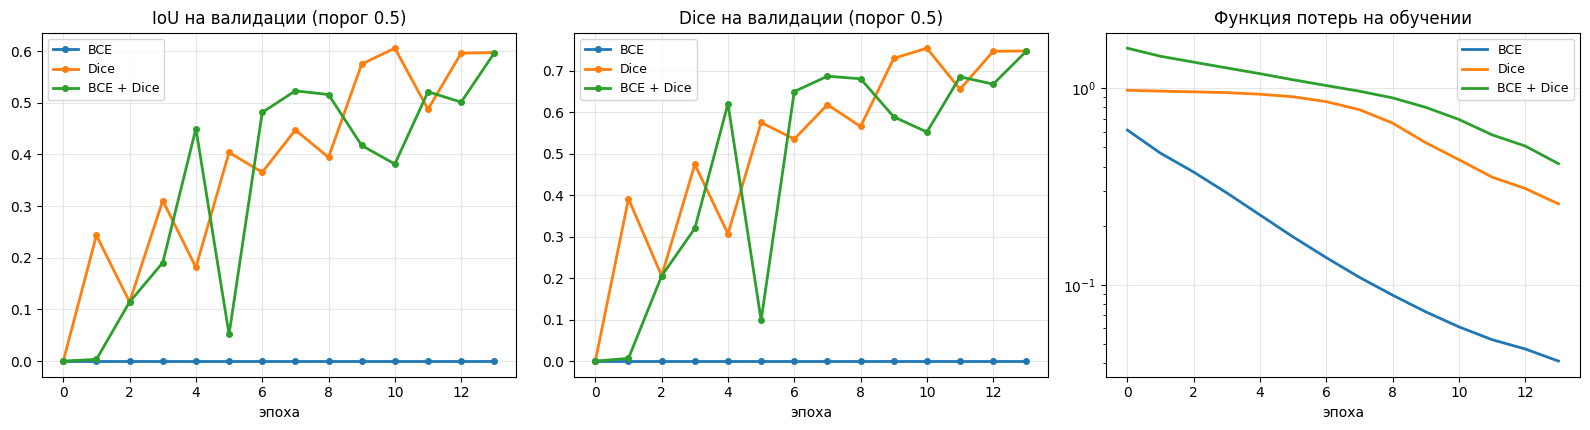

лосс         IoU (тест)       Dice     accuracy   макс. вероятн.
------------------------------------------------------------------
BCE              0.0000     0.0000       0.9926            0.443


Dice             0.5996     0.7497       0.9964            1.000
BCE + Dice       0.5711     0.7270       0.9959            1.000


In [24]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
for i, (name, h) in enumerate(hists.items()):
    axes[0].plot(h["val_iou"], color="C%d" % i, lw=2, marker="o", ms=4, label=name)
    axes[1].plot(h["val_dice"], color="C%d" % i, lw=2, marker="o", ms=4, label=name)
    axes[2].plot(h["train_loss"], color="C%d" % i, lw=2, label=name)
axes[0].set_title("IoU на валидации (порог 0.5)")
axes[1].set_title("Dice на валидации (порог 0.5)")
axes[2].set_title("Функция потерь на обучении")
axes[2].set_yscale("log")
for ax in axes:
    ax.set_xlabel("эпоха"); ax.grid(alpha=0.3); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

print("%-12s %10s %10s %12s %16s" % ("лосс", "IoU (тест)", "Dice", "accuracy",
                                    "макс. вероятн."))
print("-" * 66)
for name, m in models.items():
    proba = predict_proba(m, X_te)
    pred = (proba > 0.5).float()
    print("%-12s %10.4f %10.4f %12.4f %16.3f"
          % (name, iou_score(pred, Y_te_bin), dice_score(pred, Y_te_bin),
             pixel_accuracy(pred, Y_te_bin), proba.max()))

⚠️ **Правую панель нельзя читать как сравнение.** Три кривые — это три **разные**
функции: BCE измеряется в натах на пиксель, Dice loss живёт в диапазоне 0…1, а их сумма —
просто сумма. Осмысленно только то, падает ли каждая кривая у своего запуска; сравнивать
кривые между собой бессмысленно. Модели сравниваются по метрике — это левые две панели.

Прежде чем разбирать результат, посмотрим на **сырые вероятности**, которые выдают
три модели: там видно то, чего в метриках не видно.

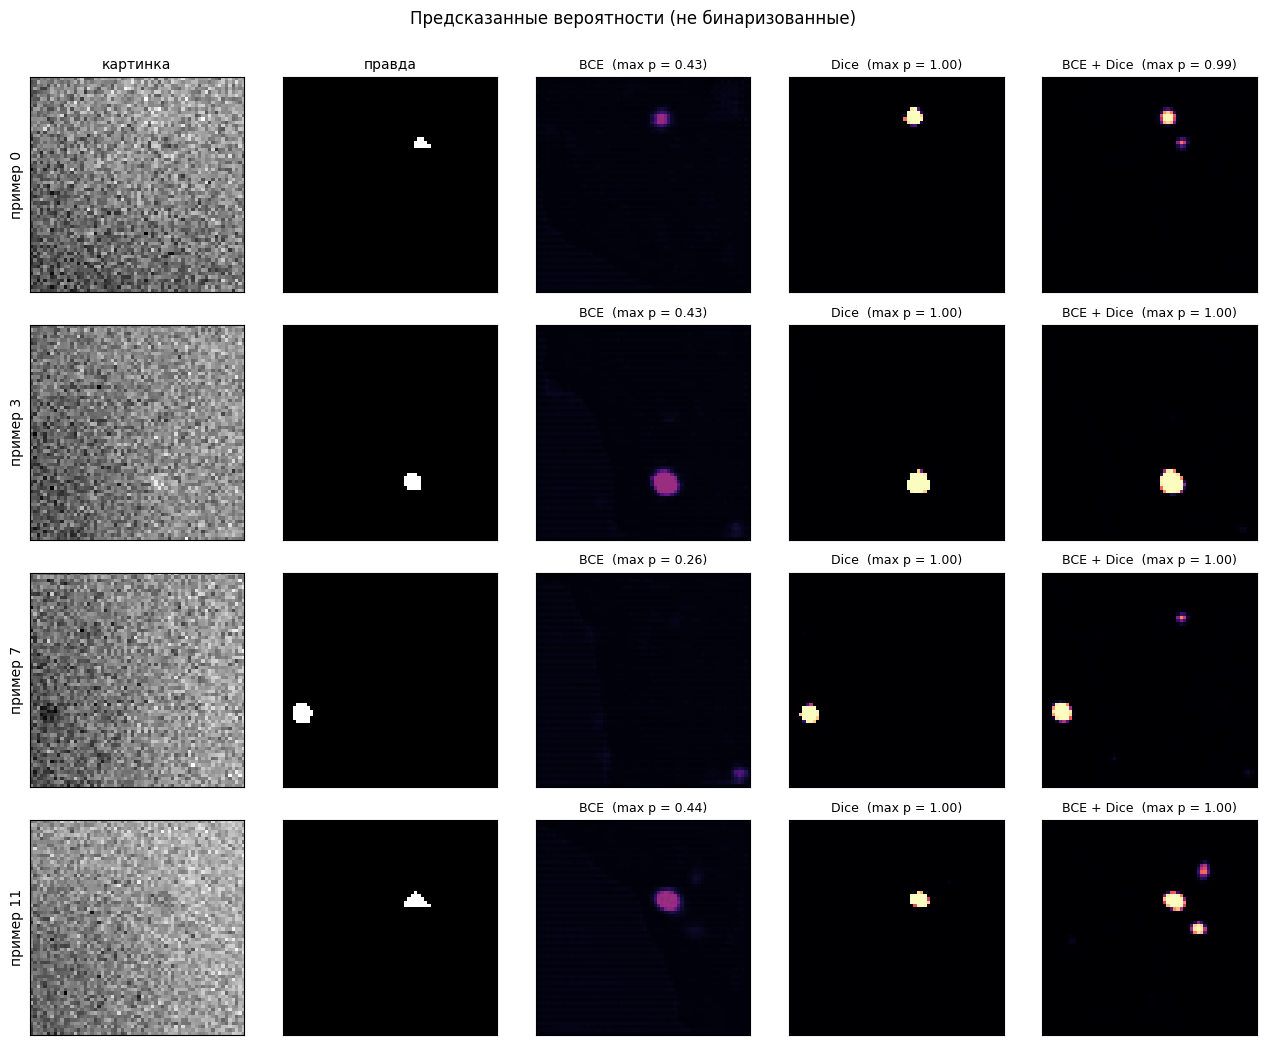

In [25]:
idx = [0, 3, 7, 11]
fig, axes = plt.subplots(len(idx), 5, figsize=(13, 2.6 * len(idx)))
for r, j in enumerate(idx):
    img = X_te[j, 0].numpy(); truth = Y_te_bin[j, 0].numpy()
    axes[r, 0].imshow(img, cmap="gray"); axes[r, 0].set_ylabel("пример %d" % j, fontsize=10)
    axes[r, 1].imshow(truth, cmap="gray", vmin=0, vmax=1)
    for c, (name, m) in enumerate(models.items()):
        p = predict_proba(m, X_te[j:j + 1])[0, 0].numpy()
        axes[r, 2 + c].imshow(p, cmap="magma", vmin=0, vmax=1)
        axes[r, 2 + c].set_title("%s  (max p = %.2f)" % (name, p.max()), fontsize=9)
    for ax in axes[r]:
        ax.set_xticks([]); ax.set_yticks([])
axes[0, 0].set_title("картинка", fontsize=10)
axes[0, 1].set_title("правда", fontsize=10)
plt.suptitle("Предсказанные вероятности (не бинаризованные)", y=1.0)
plt.tight_layout(); plt.show()

### Разбор

Числа с теста при пороге 0.5: **BCE — IoU 0.0000, Dice loss — 0.5996, BCE + Dice — 0.5711.**
Тезис лекции «при сильном дисбалансе BCE проигрывает Dice» подтвердился в самой жёсткой
форме, какая возможна: у BCE IoU равен нулю на **всех четырнадцати** эпохах. При этом
pixel accuracy у него 0.9926 — ровно та метрика-обманка из раздела 2.

⚠️ Но метрики здесь мало, и картинка с вероятностями показывает, что на самом деле
произошло. **BCE объект нашёл.** На его картах отчётливо видно пятно ровно там, где
объект (плюс слабая подсветка фона и иногда лишнее пятно — но основное на месте).
Просто максимальная вероятность, которую он выдаёт на всём тесте, — **0.443**,
а режем мы по 0.5. Ни один пиксель порог не переходит, и IoU честно равен нулю.

Значит, точная формулировка не «BCE не работает при дисбалансе», а: **BCE, обученный
на данных с 0.7% положительного класса, систематически недооценивает вероятность
объекта.** Он минимизирует среднюю ошибку по пикселям, а при таком дисбалансе средняя
ошибка меньше, когда модель осторожничает. У Dice loss этой проблемы нет по построению:
в его формуле нет TN, поэтому осторожность ничем не вознаграждается — и его вероятности
уходят к 1.000.

Посмотрите ещё раз на правую панель предыдущего графика: **у BCE функция потерь падает
быстрее и глубже всех** (0.61 → 0.04), а метрика всё это время ноль. Падающий лосс сам
по себе не значит ничего — это и есть причина, по которой на валидации логируют метрику
задачи, а не только функцию потерь.

⚠️ А вот чего измерение **не** подтвердило: **комбинация BCE + Dice не выиграла**
у чистого Dice (0.5711 против 0.5996). Она не хуже, но и не лучше, и разница — в пределах
шума одного запуска: посмотрите, как скачут кривые на левой панели — у Dice соседние эпохи
дают 0.606 → 0.487 → 0.596. На больших задачах сумму берут потому, что BCE даёт
устойчивый попиксельный градиент на ранних эпохах, а Dice тянет нужную метрику; на нашей
игрушечной задаче этот эффект просто не проявился. Делать из одного запуска вывод
«комбинация не нужна» нельзя — как и обратный.

---

## 7. Порог бинаризации

Модель отдаёт вероятность для каждого пикселя, а метрика считается по бинарной маске.
Между ними стоит **порог**, и 0.5 в нём — не закон природы, а привычка.

Построим зависимость IoU от порога на валидации.

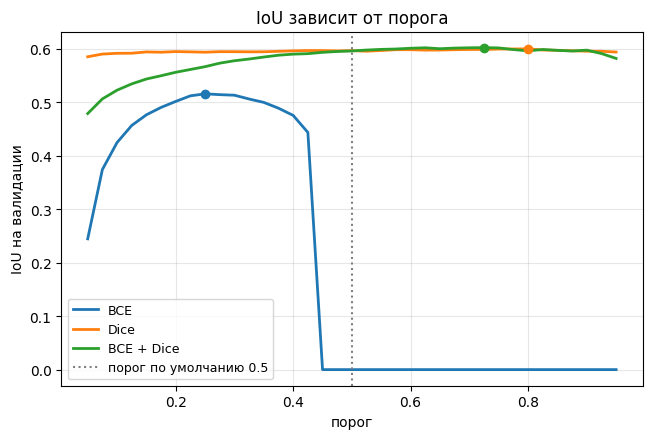

лосс         порог 0.5 (val)   лучший порог IoU на нём (val)        прирост
------------------------------------------------------------------------
BCE                  0.0000          0.250         0.5162        +0.5162
Dice                 0.5970          0.800         0.6004        +0.0034
BCE + Dice           0.5964          0.725         0.6027        +0.0063


In [26]:
thresholds = np.arange(0.05, 0.96, 0.025)
proba_va = {name: predict_proba(m, X_va) for name, m in models.items()}
proba_te = {name: predict_proba(m, X_te) for name, m in models.items()}

curves, best = {}, {}
for name, p in proba_va.items():
    vals = [iou_score((p > t).float(), Y_va_bin) for t in thresholds]
    curves[name] = np.array(vals)
    best[name] = float(thresholds[int(np.nanargmax(vals))])

plt.figure(figsize=(7.5, 4.6))
for i, (name, vals) in enumerate(curves.items()):
    plt.plot(thresholds, vals, color="C%d" % i, lw=2, label=name)
    plt.scatter([best[name]], [np.nanmax(vals)], color="C%d" % i, zorder=3)
plt.axvline(0.5, color="gray", ls=":", label="порог по умолчанию 0.5")
plt.xlabel("порог"); plt.ylabel("IoU на валидации")
plt.title("IoU зависит от порога"); plt.legend(fontsize=9); plt.grid(alpha=0.3)
plt.show()

print("%-12s %14s %14s %14s %14s" % ("лосс", "порог 0.5 (val)", "лучший порог",
                                     "IoU на нём (val)", "прирост"))
print("-" * 72)
for name in models:
    at_half = iou_score((proba_va[name] > 0.5).float(), Y_va_bin)
    at_best = float(np.nanmax(curves[name]))
    print("%-12s %14.4f %14.3f %14.4f %14s"
          % (name, at_half, best[name], at_best, "%+.4f" % (at_best - at_half)))

⚠️ Порог подобран **по валидации**, и мерить на ней же после этого нечестно: мы выбрали
максимум из 37 вариантов, а значит частично подстроились под шум этой выборки.
Честная проверка — перенести выбранный порог на тест, который в подборе не участвовал.

In [27]:
print("%-12s %16s %16s %14s" % ("лосс", "IoU на тесте@0.5", "IoU на тесте@подобр.", "прирост"))
print("-" * 64)
for name in models:
    a = iou_score((proba_te[name] > 0.5).float(), Y_te_bin)
    b = iou_score((proba_te[name] > best[name]).float(), Y_te_bin)
    print("%-12s %16.4f %16.4f %14s" % (name, a, b, "%+.4f" % (b - a)))

# насколько оптимистична оценка, если подбирать и мерить на одной выборке
print("\nоценка на валидации (там же, где подбирали) против теста:")
for name in models:
    print("  %-12s val %.4f → test %.4f" % (name, float(np.nanmax(curves[name])),
                                            iou_score((proba_te[name] > best[name]).float(), Y_te_bin)))
print("\nпорогов перебрано:", len(thresholds))

лосс         IoU на тесте@0.5 IoU на тесте@подобр.        прирост
----------------------------------------------------------------
BCE                    0.0000           0.4848        +0.4848
Dice                   0.5996           0.5921        -0.0075
BCE + Dice             0.5711           0.5788        +0.0077

оценка на валидации (там же, где подбирали) против теста:
  BCE          val 0.5162 → test 0.4848
  Dice         val 0.6004 → test 0.5921
  BCE + Dice   val 0.6027 → test 0.5788

порогов перебрано: 37


Вот и разгадка нулевого IoU у BCE.

- **BCE: 0.0000 при пороге 0.5 и 0.5162 при пороге 0.25.** Полметрики из ниоткуда,
  без единой дополнительной эпохи обучения. На графике видно, откуда обрыв: кривая BCE
  падает в ноль около 0.44 — это его максимальная вероятность, выше не поднимается
  ни один пиксель ни на одной картинке;
- **у Dice и BCE + Dice подбор порога почти ничего не меняет** (+0.0034 и +0.0063).
  Их оптимум лежит правее середины (0.80 и 0.725), но кривая там плоская: модель уверена,
  вероятности вытолкнуты к 0 и 1, и сдвиг порога почти не меняет маску.

На тесте картина та же: у BCE 0.0000 → 0.4848, у остальных двух разница в третьем знаке
и разного знака (−0.0075 и +0.0077), то есть это шум.

⚠️ И честная цена подбора: на валидации BCE с порогом 0.25 показывал 0.5162, а на тесте
с тем же порогом — 0.4848. Три сотых IoU — плата за то, что мы выбрали лучший из 37
вариантов по конкретной выборке. У Dice и BCE + Dice сдвиг того же порядка
(0.6004 → 0.5921 и 0.6027 → 0.5788). **Порог — такой же гиперпараметр, как темп обучения:**
подбирается на валидации, докладывается на тесте.

Практический вывод, который стоит унести: **если у вас сильный дисбаланс и вы обучались
на BCE — прежде чем объявлять модель нерабочей, постройте эту кривую.** Ноль при пороге
0.5 и половина метрики при пороге 0.25 — это одна и та же модель.

---

## 8. Что дают skip-связи

Отключим `torch.cat` и обучим ровно ту же сеть заново. Всё остальное — данные, seed,
оптимизатор, функция потерь — не меняется.

⚠️ Одна оговорка сразу: в разделе 6 модели обучались 14 эпох, и кривые к концу
ещё не вышли на плато. Сравнивать архитектуры по недообученным моделям — обычный способ
получить красивый, но неверный результат: разница в скорости сходимости выглядит
как разница в качестве. Поэтому здесь **обе** сети получают вдвое больше эпох,
и мы посмотрим на обе точки — на 14-й эпохе и на 28-й.

In [28]:
SKIP_LOSS = "BCE + Dice"
LONG = 2 * EPOCHS

print("=== U-Net СО skip-связями, %d эпох (это займёт около минуты)" % LONG)
model_skip, hist_skip = train_unet(SKIP_LOSS, epochs=LONG, verbose=False)
print("    %.0f с" % hist_skip["seconds"])

print("=== U-Net БЕЗ skip-связей, %d эпох" % LONG)
model_noskip, hist_noskip = train_unet(SKIP_LOSS, epochs=LONG, use_skips=False, verbose=False)
print("    %.0f с" % hist_noskip["seconds"])

print("\nпараметров со skip:  %d" % sum(p.numel() for p in model_skip.parameters()))
print("параметров без skip: %d" % sum(p.numel() for p in model_noskip.parameters()))

# Проверка дисциплины с сидами: первые EPOCHS эпох длинного запуска обязаны
# совпасть с коротким запуском из раздела 6 — та же модель, тот же порядок батчей.
print("\nпервые %d эпох совпали с разделом 6: %s"
      % (EPOCHS, np.allclose(hist_skip["val_iou"][:EPOCHS], hists[SKIP_LOSS]["val_iou"])))

=== U-Net СО skip-связями, 28 эпох (это займёт около минуты)


    62 с
=== U-Net БЕЗ skip-связей, 28 эпох


    52 с

параметров со skip:  121033
параметров без skip: 108937

первые 14 эпох совпали с разделом 6: True


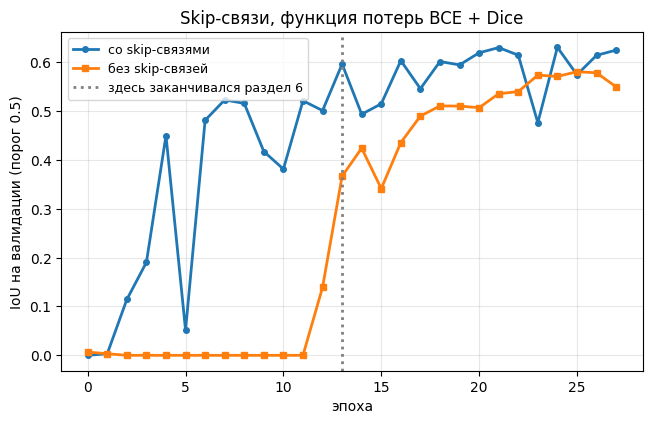

IoU на валидации, если остановиться на 14-й эпохе: со skip 0.596, без skip 0.367
IoU на валидации на 28-й эпохе:                    со skip 0.625, без skip 0.550

пикселей в полосе границы шириной ±2: 11214 (2.28% кадра)

итог на тесте после 28 эпох:
модель                  IoU     Dice   ошибок гран.   промахов IoU без промахов
----------------------------------------------------------------------------------
со skip-связями      0.6177   0.7637         12.34%      14/120           0.6708


без skip-связей      0.5268   0.6901         16.41%      20/120           0.5876


In [29]:
def boundary_band(mask, width=2):
    """Полоса вокруг границы объекта: морфологическое расширение минус сжатие."""
    k = 2 * width + 1
    dil = F.max_pool2d(mask, k, stride=1, padding=width)
    ero = -F.max_pool2d(-mask, k, stride=1, padding=width)
    return (dil - ero) > 0


band = boundary_band(Y_te_bin)

plt.figure(figsize=(7.5, 4.4))
plt.plot(hist_skip["val_iou"], lw=2, marker="o", ms=4, label="со skip-связями")
plt.plot(hist_noskip["val_iou"], lw=2, marker="s", ms=4, label="без skip-связей")
plt.axvline(EPOCHS - 1, color="gray", ls=":", lw=2,
            label="здесь заканчивался раздел 6")
plt.xlabel("эпоха"); plt.ylabel("IoU на валидации (порог 0.5)")
plt.title("Skip-связи, функция потерь %s" % SKIP_LOSS)
plt.legend(fontsize=9); plt.grid(alpha=0.3)
plt.show()

print("IoU на валидации, если остановиться на %d-й эпохе: со skip %.3f, без skip %.3f"
      % (EPOCHS, hist_skip["val_iou"][EPOCHS - 1], hist_noskip["val_iou"][EPOCHS - 1]))
print("IoU на валидации на %d-й эпохе:                    со skip %.3f, без skip %.3f"
      % (LONG, hist_skip["val_iou"][-1], hist_noskip["val_iou"][-1]))

print("\nпикселей в полосе границы шириной ±2: %d (%.2f%% кадра)"
      % (band.sum(), 100 * band.float().mean()))
print("\nитог на тесте после %d эпох:" % LONG)
print("%-18s %8s %8s %14s %10s %16s"
      % ("модель", "IoU", "Dice", "ошибок гран.", "промахов", "IoU без промахов"))
print("-" * 82)
for name, m in (("со skip-связями", model_skip), ("без skip-связей", model_noskip)):
    pred = (predict_proba(m, X_te) > 0.5).float()
    err = (pred != Y_te_bin)[band].float().mean().item()
    # промах = на картинке нет ни одного правильно найденного пикселя объекта
    per_img = [iou_score(pred[i], Y_te_bin[i]) for i in range(len(X_te))]
    miss = sum(1 for v in per_img if v == 0.0)
    found = [v for v in per_img if v > 0.0]
    print("%-18s %8.4f %8.4f %13.2f%% %7d/%d %16.4f"
          % (name, iou_score(pred, Y_te_bin), dice_score(pred, Y_te_bin), 100 * err,
             miss, len(X_te), float(np.mean(found))))

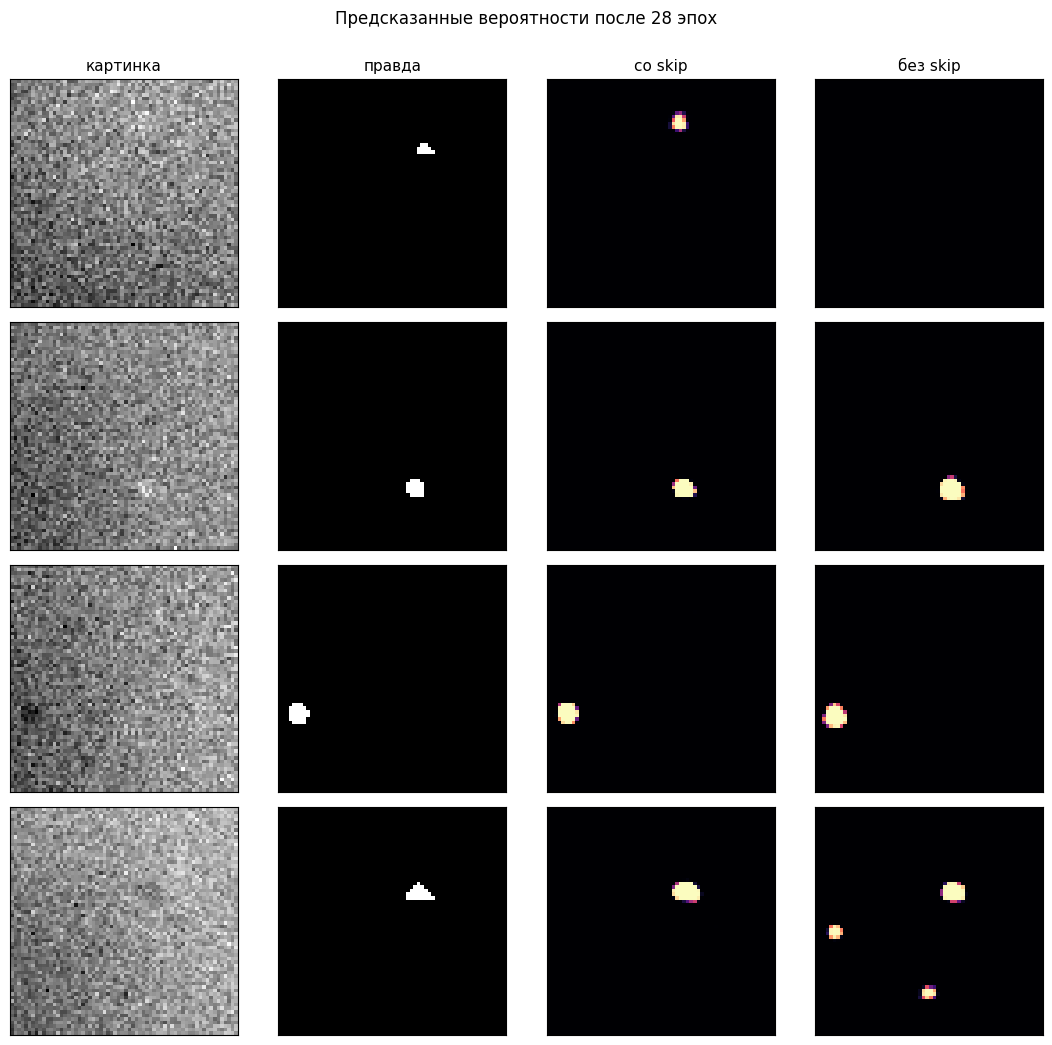

In [30]:
fig, axes = plt.subplots(len(idx), 4, figsize=(11, 2.6 * len(idx)))
for r, j in enumerate(idx):
    axes[r, 0].imshow(X_te[j, 0].numpy(), cmap="gray")
    axes[r, 1].imshow(Y_te_bin[j, 0].numpy(), cmap="gray", vmin=0, vmax=1)
    axes[r, 2].imshow(predict_proba(model_skip, X_te[j:j + 1])[0, 0].numpy(),
                      cmap="magma", vmin=0, vmax=1)
    axes[r, 3].imshow(predict_proba(model_noskip, X_te[j:j + 1])[0, 0].numpy(),
                      cmap="magma", vmin=0, vmax=1)
    for ax in axes[r]:
        ax.set_xticks([]); ax.set_yticks([])
for c, t in enumerate(["картинка", "правда", "со skip", "без skip"]):
    axes[0, c].set_title(t, fontsize=11)
plt.suptitle("Предсказанные вероятности после %d эпох" % LONG, y=1.0)
plt.tight_layout(); plt.show()

### Разбор

Skip-связи здесь выигрывают — и по IoU, и по ошибкам на границе. Но интереснее то,
**насколько результат зависит от того, где остановиться.**

Если бы мы взяли те же 14 эпох, что в разделе 6, разрыв выглядел бы огромным: **0.596
против 0.367** по IoU на валидации, почти вдвое. Но сеть без skip-связей в этот момент
просто ещё не разогналась — двенадцать эпох она стояла на нуле и пошла вверх только
на тринадцатой. К 28-й эпохе обе выходят на плато, и разрыв по валидации сжимается
**втрое**: 0.625 против 0.550 вместо 0.596 против 0.367.

⚠️ Это и есть главный методический урок раздела: **половина «преимущества архитектуры»
в таком замере — это преимущество в скорости сходимости, а не в качестве.** Замерь мы
на 14-й эпохе и напиши «skip-связи дают +0.23 IoU» — формально правда, по сути враньё.

Что остаётся после того, как обе сети доучены (числа с теста):

| | со skip | без skip |
|---|---|---|
| IoU | 0.6177 | 0.5268 |
| ошибок в полосе ±2 пикселя от границы | 12.34% | 16.41% |
| картинок, где объект не найден вовсе | 14 из 120 | 20 из 120 |
| средний IoU по картинкам, где объект найден | 0.6708 | 0.5876 |

Разложение по последним двум строкам показывает, что skip-связи выигрывают **по обеим
причинам сразу**: без них сеть и чаще теряет объект целиком (20 промахов против 14),
и хуже обводит те, которые нашла (0.588 против 0.671). Вторая строка — это ровно тезис
лекции «энкодер понимает **что**, но забывает **где**»: без прямого канала от `enc1`
информация о точном положении границы должна пройти через горлышко 8×8 и вернуться,
и часть её там теряется.

А вот чего на картинках **не** видно — так это ожидаемой «размытости». Пятна у обеих
сетей компактные и уверенные. Разница проявляется иначе: на первом примере сеть
без skip-связей не нашла объект вообще (это самый маленький объект из четырёх),
а на четвёртом выдала два лишних пятна на пустом месте.

⚠️ Две честные оговорки:

1. **Сравнение не идеально контролируемое.** У сети со skip-связями на 11% больше
   параметров (121 033 против 108 937): после `torch.cat` вход в каждый блок декодера
   вдвое шире, и свёртки в нём больше. Часть выигрыша может быть просто от размера.
   Чтобы отделить одно от другого, надо уравнять число параметров, расширив декодер
   безскиповой версии, — хорошее упражнение.
2. **IoU 0.6 — это не «плохая архитектура».** Наша задача трудная: контраст фигуры
   соизмерим с шумом, объект занимает 0.7% кадра. Для сети на 121 тысячу параметров,
   обученной 28 эпох на 400 картинках, это честный потолок.

---

## 9. Аугментации: маска едет вместе с картинкой

В классификации аугментация применяется к картинке, а метка остаётся прежней: повёрнутая
кошка — всё ещё кошка. **В сегментации метка — это тоже картинка**, и её нужно
преобразовать точно так же. Отсюда два подводных камня, оба встречаются в чужом коде
регулярно.

### 9.1. Подводный камень первый: рассинхрон

Если вызвать случайное преобразование для картинки и для маски по отдельности,
каждое из них бросит **свою** монетку, и разметка перестанет соответствовать картинке.
Модель после этого учится на шуме и молча учится плохо: ошибки нет, loss падает,
качество не растёт.

In [ ]:
def augment_wrong(img, mask, gen):
    """ТАК ДЕЛАТЬ НЕЛЬЗЯ: два независимых броска монетки."""
    flip_img = torch.rand(1, generator=gen).item() < 0.5
    flip_mask = torch.rand(1, generator=gen).item() < 0.5     # ← отдельный бросок!
    if flip_img:
        img = torch.flip(img, dims=[-1])
    if flip_mask:
        mask = torch.flip(mask, dims=[-1])
    return img, mask, flip_img, flip_mask


def augment_right(img, mask, gen):
    """Правильно: решение принимается ОДИН раз и применяется к обоим."""
    if torch.rand(1, generator=gen).item() < 0.5:
        img, mask = torch.flip(img, dims=[-1]), torch.flip(mask, dims=[-1])
    k = int(torch.randint(0, 4, (1,), generator=gen).item())
    if k:
        img, mask = torch.rot90(img, k, dims=(-2, -1)), torch.rot90(mask, k, dims=(-2, -1))
    return img, mask


def contrast(img, mask):
    """Насколько объект отличается от фона ПО ЭТОЙ маске.

    Если маска соответствует картинке, разность средних яркостей заметна.
    Если маска уехала — она накрывает случайный кусок фона, и разность падает
    почти до нуля. Это измеримый признак рассинхрона, не требующий знать,
    какие именно преобразования применились.
    """
    inside = img[mask > 0].mean()
    outside = img[mask == 0].mean()
    return abs(float(inside - outside))

# albumentations

In [32]:
n = 200
gen = torch.Generator().manual_seed(0)
flags, iou_wrong, c_before, c_wrong, c_right = [], [], [], [], []

for i in range(n):
    img, m = X_tr[i], Y_tr_bin[i]
    c_before.append(contrast(img, m))

    aug_img, aug_mask, flip_img, flip_mask = augment_wrong(img, m, gen)
    correct_mask = torch.flip(m, dims=[-1]) if flip_img else m      # чем маска ДОЛЖНА была стать
    flags.append(flip_img != flip_mask)                             # рассинхрон?
    iou_wrong.append(iou_score(aug_mask, correct_mask))
    c_wrong.append(contrast(aug_img, aug_mask))

    r_img, r_mask = augment_right(img, m, gen)
    c_right.append(contrast(r_img, r_mask))

desync = sum(flags)
bad_iou = [v for v, f in zip(iou_wrong, flags) if f]
bad_c = [v for v, f in zip(c_wrong, flags) if f]
ok_c = [v for v, f in zip(c_wrong, flags) if not f]

print("НЕПРАВИЛЬНАЯ аугментация (два независимых броска монетки):")
print("  рассинхрон случился в %d парах из %d" % (desync, n))
print("  средний IoU маски с правильной, по всем парам:        %.3f" % np.mean(iou_wrong))
print("  то же, ТОЛЬКО по рассинхронизированным парам:         %.3f" % np.mean(bad_iou))
print("  контраст объект/фон по маске: исходно                 %.3f" % np.mean(c_before))
print("    у пар, где монетки совпали:                         %.3f" % np.mean(ok_c))
print("    у пар, где монетки разошлись:                       %.3f" % np.mean(bad_c))
print("\nПРАВИЛЬНАЯ аугментация (один бросок на пару):")
print("  контраст объект/фон по маске: было %.3f → стало %.3f"
      % (np.mean(c_before), np.mean(c_right)))
print("  контраст сохранился у всех %d пар: %s"
      % (n, all(abs(a - b) < 1e-6 for a, b in zip(c_before, c_right))))

НЕПРАВИЛЬНАЯ аугментация (два независимых броска монетки):
  рассинхрон случился в 96 парах из 200
  средний IoU маски с правильной, по всем парам:        0.539
  то же, ТОЛЬКО по рассинхронизированным парам:         0.039
  контраст объект/фон по маске: исходно                 0.140
    у пар, где монетки совпали:                         0.136
    у пар, где монетки разошлись:                       0.053

ПРАВИЛЬНАЯ аугментация (один бросок на пару):
  контраст объект/фон по маске: было 0.140 → стало 0.140
  контраст сохранился у всех 200 пар: True


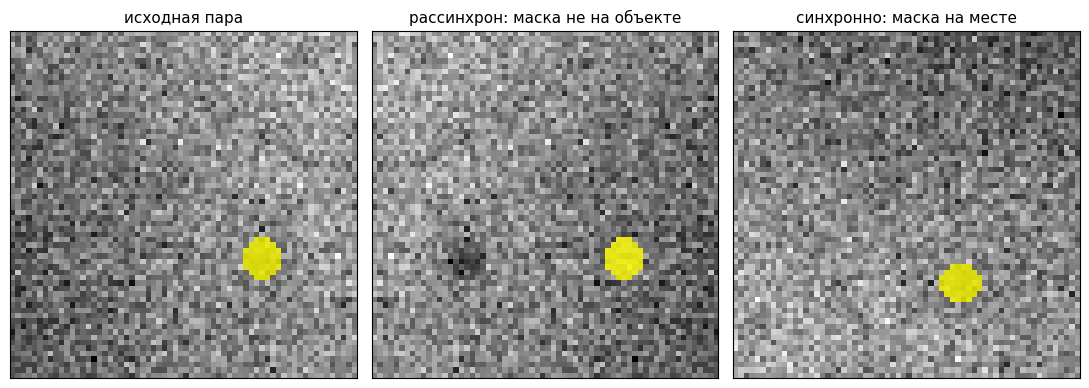

In [33]:
gen = torch.Generator().manual_seed(3)
img, m = X_tr[1], Y_tr_bin[1]
# ищем бросок, при котором рассинхрон действительно случился
for _ in range(20):
    aug_img, aug_mask, fi, fm = augment_wrong(img, m, gen)
    if fi != fm:
        break
r_img, r_mask = augment_right(img, m, gen)

panels = [(img[0], m[0], "исходная пара"),
          (aug_img[0], aug_mask[0], "рассинхрон: маска не на объекте"),
          (r_img[0], r_mask[0], "синхронно: маска на месте")]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
for ax, (a, b, title) in zip(axes, panels):
    ax.imshow(a.numpy(), cmap="gray")
    ax.imshow(np.ma.masked_where(b.numpy() == 0, b.numpy()), cmap="autumn",
              alpha=0.8, vmin=0, vmax=1, interpolation="nearest")
    ax.set_title(title, fontsize=11); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

Монетки разошлись в 96 парах из 200 — это и есть частота поломки: **почти каждый второй
объект в обучающей выборке оказался бы размечен по пустому месту.**

Числа: у рассинхронизированных пар средний IoU маски с правильной — **0.039**, а контраст
падает почти втрое, с 0.136 до **0.053**. В ноль он не уходит только потому, что фон
у нас неоднородный: случайный его кусок всё равно чуть отличается по яркости от остального
кадра. Но сигнала «под маской объект» в такой паре нет.

У правильной версии контраст сохраняется **точно** (0.140 → 0.140, у всех 200 пар):
флипы и повороты на 90° только переставляют пиксели, поэтому множество значений
под маской не меняется вообще.

⚠️ Главное в этом сюжете — не то, что ошибка есть, а то, что она **молчит**. Исключения
не будет, формы тензоров сойдутся, loss будет падать (сеть выучит предсказывать что-то
среднее), и единственный симптом — качество, которое необъяснимо не растёт. Ровно поэтому
пару «картинка + маска» после аугментации стоит один раз посмотреть глазами, как мы
сейчас и сделали.

### 9.2. Подводный камень второй: интерполяция маски

Флипы и повороты на 90° точны — они просто переставляют пиксели. А поворот на произвольный
угол, масштабирование и `resize` **интерполируют**. Для картинки это нормально, для маски —
нет: билинейная интерполяция усредняет соседние **номера классов**, и между классом 0
и классом 3 появляется «класс 1.5». После округления получаются объекты классов,
которых на картинке нет вообще.

Проверим на маске, где есть только классы 0 (фон) и 3 (треугольник).

In [34]:
src = torch.zeros(1, 1, SIZE, SIZE)
j = int((Y_tr == 3).flatten(1).any(1).nonzero()[0])      # первая картинка с треугольником
src[0, 0] = (Y_tr[j] == 3).float() * 3.0                 # только классы 0 и 3
print("классы в исходной маске:", sorted(set(src.unique().int().tolist())))

angle = 0.5                                              # ≈ 29°
theta = torch.tensor([[[np.cos(angle), -np.sin(angle), 0.],
                       [np.sin(angle), np.cos(angle), 0.]]], dtype=torch.float32)
grid = F.affine_grid(theta, src.shape, align_corners=False)
rot_bilinear = F.grid_sample(src, grid, mode="bilinear", align_corners=False)
rot_nearest = F.grid_sample(src, grid, mode="nearest", align_corners=False)

print("\nbilinear: различных значений %d, диапазон %.3f…%.3f"
      % (len(rot_bilinear.unique()), rot_bilinear.min(), rot_bilinear.max()))
print("          после округления получились классы:",
      sorted(set(rot_bilinear.round().int().unique().tolist())))
ghost = ((rot_bilinear.round() == 1) | (rot_bilinear.round() == 2)).sum().item()
print("          пикселей с НЕСУЩЕСТВУЮЩИМИ классами 1 и 2: %d" % ghost)

print("\nnearest:  различных значений %d → классы %s"
      % (len(rot_nearest.unique()), sorted(set(rot_nearest.int().unique().tolist()))))
print("          пикселей с несуществующими классами: %d"
      % ((rot_nearest == 1) | (rot_nearest == 2)).sum().item())

классы в исходной маске: [0, 3]

bilinear: различных значений 32, диапазон 0.000…3.000
          после округления получились классы: [0, 1, 2, 3]
          пикселей с НЕСУЩЕСТВУЮЩИМИ классами 1 и 2: 15

nearest:  различных значений 2 → классы [0, 3]
          пикселей с несуществующими классами: 0


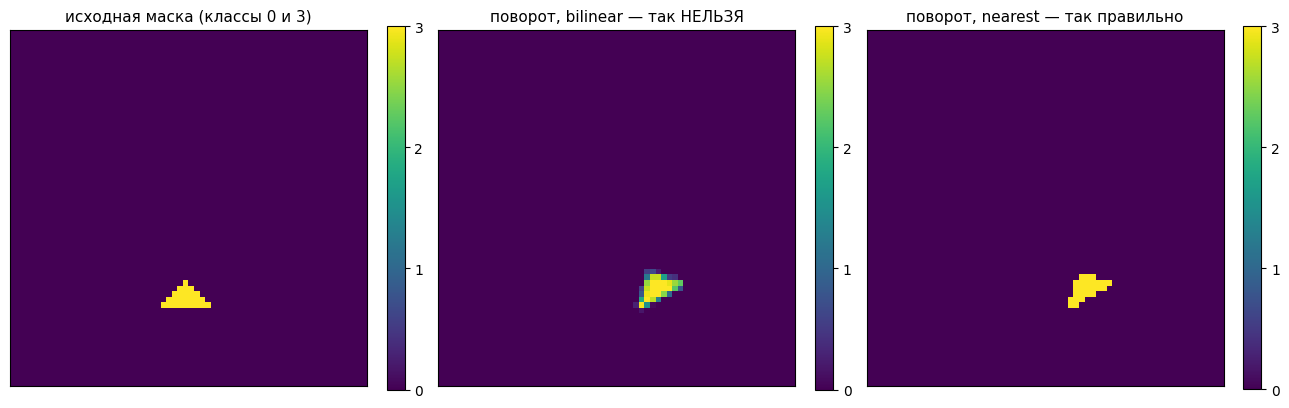

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.0))
for ax, (a, title) in zip(axes, [
        (src, "исходная маска (классы 0 и 3)"),
        (rot_bilinear, "поворот, bilinear — так НЕЛЬЗЯ"),
        (rot_nearest, "поворот, nearest — так правильно")]):
    im = ax.imshow(a[0, 0].numpy(), cmap="viridis", vmin=0, vmax=3, interpolation="nearest")
    ax.set_title(title, fontsize=11); ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(im, ax=ax, fraction=0.046, ticks=[0, 1, 2, 3])
plt.tight_layout(); plt.show()

Правило: **картинку интерполируем чем угодно (bilinear, bicubic), маску — только
`nearest`.** В библиотеках аугментации (`albumentations`, `torchvision.transforms.v2`)
для этого есть отдельный тип цели: вы объявляете тензор маской, и библиотека сама
выбирает `nearest` и синхронизирует случайные параметры между картинкой и маской.
Писать это руками имеет смысл ровно один раз — чтобы понимать, что именно библиотека
за вас делает.

⚠️ Отдельная тонкость для **бинарных** масок: там «фантомных классов» не будет
(значения между 0 и 1 после порога 0.5 схлопнутся в 0 или 1), но границы объекта
всё равно поедут на полпикселя. Для многоклассовой разметки последствия уже
катастрофические — что мы и увидели.

---

## 10. Что попробовать самостоятельно

1. **`pos_weight` — третий способ бороться с дисбалансом.** У `BCEWithLogitsLoss`
   есть аргумент `pos_weight`: он домножает вклад положительного класса.
   Обучите модель с `nn.BCEWithLogitsLoss(pos_weight=torch.tensor(100.0))`
   (добавьте её в словарь `LOSSES` и вызовите `train_unet`). Ожидаемый результат:
   в отличие от обычного BCE, IoU при пороге 0.5 перестаёт быть нулевым уже
   на первых эпохах. Почему 100 — откуда берётся порядок этого числа?
   Подсказка: посмотрите на долю пикселей объекта из раздела 1.

2. **Арифметика транспонированной свёртки.** Функцией `out_size` найдите все наборы
   `(kernel, padding, output_padding)` при `stride = 2`, которые превращают 16 в 32.
   Ответ: их ровно столько же, сколько для 8 → 16, и это те же наборы —
   объясните, почему размер входа на ответ не влияет.

3. **Шахматные артефакты при других параметрах.** Постройте `contribution_map`
   для пар `(kernel, stride)` = `(5, 2)`, `(6, 3)`, `(6, 4)` и `(4, 4)`.
   Ожидаемый ответ: `std = 0` получится ровно у тех пар, где `kernel` делится
   на `stride` — то есть у `(6, 3)` и `(4, 4)`; у `(5, 2)` и `(6, 4)` разброс
   ненулевой. Не забудьте, что поля шириной `kernel − stride` надо обрезать.
   Отдельно посмотрите на `(4, 4)`: почему у него вкладов ровно по одному?

4. **Dice loss: по картинкам или по батчу.** В `dice_loss` мы усредняем Dice
   по картинкам (`dim=(1,2,3)`, потом `.mean()`). Сделайте вариант, который считает
   один Dice на весь батч (суммирование по всем размерностям сразу), и сравните
   значения на одном и том же батче. Это ровно та же развилка, что в разделе 2.4 —
   убедитесь, что числа разные, и подумайте, какой вариант честнее при картинках
   разного размера объекта.

5. **Цена порога, подобранного не на той выборке.** В разделе 7 мы подбирали порог
   на валидации и мерили на тесте. Подберите порог **на тесте** и сравните с честным
   числом. Насколько велик оптимистический сдвиг? Повторите для всех трёх моделей —
   у какой он больше и почему?

6. **Аугментации в обучении.** Вставьте `augment_right` в цикл обучения (применять
   к батчу целиком проще всего) и обучите модель заново. На нашем синтетическом
   датасете из 400 картинок аугментации могут и не помочь — проверьте и объясните
   результат: чего в этих данных нет такого, ради чего аугментации придуманы?